In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("property_data.csv")
test = pd.read_csv("test.csv")
sample = pd.read_csv("sample_submission.csv")

In [2]:
# Display the first five rows
df.head()


,Unnamed: 0,Property_id,property_type,offer,governorate,bedrooms,bathrooms,rent,location,city,...,is_super_agent,broker_id,floor_plans,is_featured,is_premium,description,is_verified,is_verified.1,is_exclusive,is_exclusive.1
0,27387,7343b863-a2cb-4d85-b2dd-935ea61365ff,Apartment,Residential for Rent,"Capital Governorate, Manama",studio,1,245.0,NaN,NaN,...,True,1031.0,NaN,False,False,A different furnished studio opportunity in Sa...,False,False,False,False
1,18554,f1a36ab5-1601-4127-a7a7-5095f167acca,Apartment,Rent,Capital Governorate,1,1,300.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9295,bf629ae9-a3b2-4c2e-8e0e-b0ffce916fa7,Compound,Rent,Northern Governorate,5,5,1200.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,28118,26707746-825c-4d65-b63c-dfaa69421365,Apartment,Residential for Rent,Capital Governorate,3,3,600.0,NaN,NaN,...,False,15.0,NaN,True,False,Spacious 3 Bedroom Apartment for Rent in Seef ...,False,False,False,False
4,689,dbc18ce8-1481-480c-9b66-a42653038408,Apartment,for rent,Muharraq Governorate,1,2,450.0,Al Marsa Floating City,Amwaj Islands,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Check the dataset dimensions
df.shape

(32090, 41)

In [4]:
# Check column names and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32090 entries, 0 to 32089
Data columns (total 41 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         32090 non-null  int64  
 1   Property_id        32090 non-null  str    
 2   property_type      32090 non-null  str    
 3   offer              32090 non-null  str    
 4   governorate        32090 non-null  str    
 5   bedrooms           32078 non-null  str    
 6   bathrooms          32086 non-null  str    
 7   rent               32090 non-null  float64
 8   location           2899 non-null   str    
 9   city               8206 non-null   str    
 10  area_sqm           32090 non-null  str    
 11  listing_date       22564 non-null  str    
 12  Property_id.1      32090 non-null  str    
 13  URL                23884 non-null  str    
 14  include_w_e        23884 non-null  str    
 15  title              23884 non-null  str    
 16  area               23884 non-null

In [5]:
# Summary statistics
df.describe()


,Unnamed: 0,rent,price_per_sqm,down_payment,plot_size_sqm,completion_status,latitude,longitude,agent_id,broker_id,floor_plans
count,32090.000000,32090.000000,0.0,0.0,2462.000000,0.0,14358.000000,14358.000000,14358.000000,14358.000000,0.0
mean,17827.171486,695.558461,NaN,NaN,390.279854,NaN,26.224542,50.577655,5666.473813,15935.748572,NaN
std,10288.466617,6643.256725,NaN,NaN,184.871954,NaN,0.046865,0.063542,1945.135671,50378.147908,NaN
min,0.000000,50.000000,NaN,NaN,1.000000,NaN,25.833925,50.447472,278.000000,2.000000,NaN
25%,8931.250000,330.000000,NaN,NaN,300.000000,NaN,26.203079,50.536999,4625.000000,180.000000,NaN
50%,17842.500000,450.000000,NaN,NaN,350.000000,NaN,26.213165,50.584755,6070.000000,776.000000,NaN
75%,26743.750000,700.000000,NaN,NaN,450.000000,NaN,26.241751,50.609001,7385.000000,1136.000000,NaN
max,35658.000000,950000.000000,NaN,NaN,3500.000000,NaN,26.319105,50.680939,8054.000000,190516.000000,NaN


In [6]:
# Check missing values
df.isnull().sum().sort_values(ascending=False)


price_per_sqm        32090
completion_status    32090
floor_plans          32090
down_payment         32090
payment_methods      31872
plot_size_sqm        29628
location             29191
city                 23884
availability_date    23024
agency               22564
furnished            17746
is_premium           17732
description          17732
is_verified          17732
is_verified.1        17732
is_exclusive         17732
is_exclusive.1       17732
broker_id            17732
is_featured          17732
latitude             17732
longitude            17732
location_full        17732
is_super_agent       17732
agent_id             17732
period               17732
listing_date          9526
amenities             8525
include_w_e           8206
URL                   8206
title                 8206
area                  8206
bedrooms                12
bathrooms                4
rent                     0
property_type            0
offer                    0
governorate              0
P

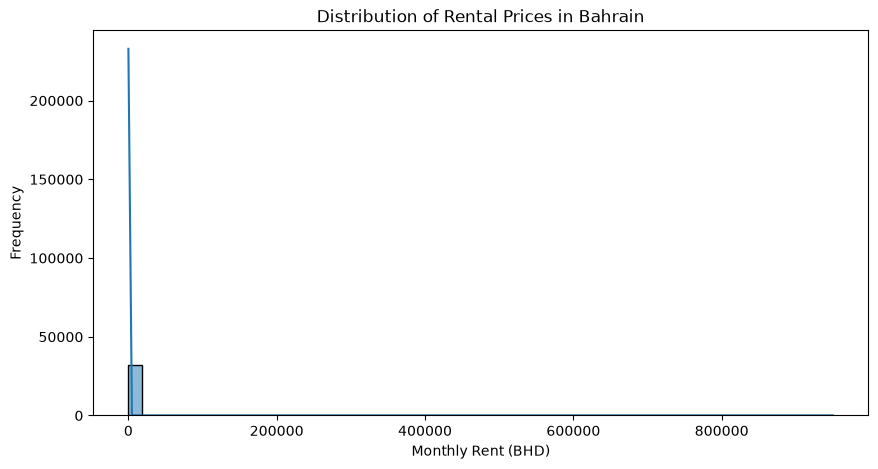

In [7]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='rent', bins=50, kde=True)

plt.title('Distribution of Rental Prices in Bahrain')
plt.xlabel('Monthly Rent (BHD)')
plt.ylabel('Frequency')
plt.show()

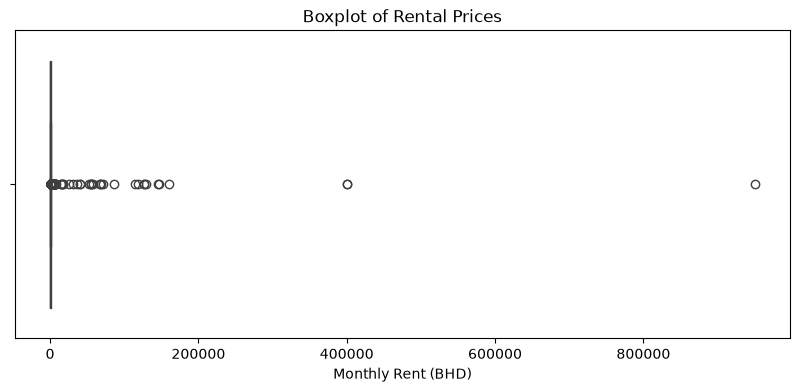

In [8]:
plt.figure(figsize=(10, 4))

sns.boxplot(data=df, x='rent')

plt.title('Boxplot of Rental Prices')
plt.xlabel('Monthly Rent (BHD)')
plt.show()

In [9]:
df.sort_values(by='rent', ascending=False)[
    ['property_type', 'governorate', 'bedrooms',
     'bathrooms', 'area_sqm', 'rent']
].head(15)

,property_type,governorate,bedrooms,bathrooms,area_sqm,rent
16545,Apartment,"Muharraq Governorate, Amwaj Islands",3,4,186.0,950000.0
3795,Villa,Southern Governorate,4,6,545.0,400000.0
23435,Villa,Southern Governorate,4+ Maid,6,"5,866 sqft / 545 sqm",400000.0
16257,Villa,"Muharraq Governorate, Diyar Al Muharraq",5,6,260.0,160000.0
16174,Villa,Northern Governorate,4+ Maid,5,"4,844 sqft / 450 sqm",146500.0
3360,Villa,Muharraq Governorate,5,7+,"5,813 sqft / 540 sqm",145000.0
23873,Villa,Northern Governorate,4,5,"2,939 sqft / 273 sqm",130000.0
9298,Apartment,"Muharraq Governorate, Diyar Al Muharraq",2,2,100.0,127000.0
16374,Villa,Northern Governorate,4,5,198.0,126000.0
13064,Land,Central Governorate,NaN,NaN,500.0,118000.0


In [10]:
print("Rent > 2,000:", (df['rent'] > 2000).sum())
print("Rent > 5,000:", (df['rent'] > 5000).sum())
print("Rent > 10,000:", (df['rent'] > 10000).sum())
print("Rent > 50,000:", (df['rent'] > 50000).sum())

Rent > 2,000: 264
Rent > 5,000: 42
Rent > 10,000: 31
Rent > 50,000: 21


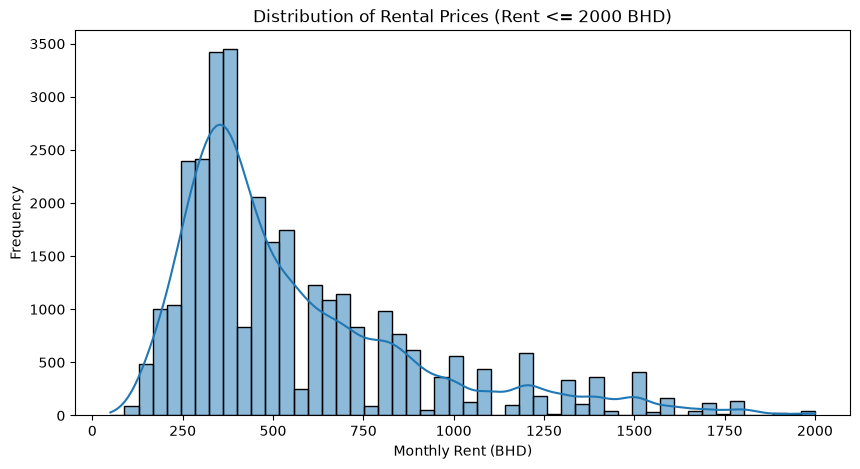

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df['rent'] <= 2000],
    x='rent',
    bins=50,
    kde=True
)

plt.title('Distribution of Rental Prices (Rent <= 2000 BHD)')
plt.xlabel('Monthly Rent (BHD)')
plt.ylabel('Frequency')
plt.show()

In [12]:
# Check listing types
df['offer'].value_counts(dropna=False)

offer
Residential for Rent    14358
Rent                     9526
for rent                 8206
Name: count, dtype: int64

In [13]:
# Check offer types for expensive properties
df[df['rent'] > 10000]['offer'].value_counts(dropna=False)

offer
Residential for Rent    16
Rent                    15
Name: count, dtype: int64

In [14]:
# Inspect the expensive listings
df[df['rent'] > 10000][
    ['property_type', 'offer', 'period', 'rent', 'title']
].sort_values('rent', ascending=False).head(15)

,property_type,offer,period,rent,title
16545,Apartment,Residential for Rent,monthly,950000.0,3 BR Apartment with Private Pool and Water View
23435,Villa,Rent,NaN,400000.0,Spacious Villa | Patel 5 | 4 Bedrooms
3795,Villa,Residential for Rent,monthly,400000.0,Spacious Villa | Patel 5 | 4 Bedrooms
16257,Villa,Residential for Rent,monthly,160000.0,URGENT SALE PRIMLOCATION I SPACIOUS I CORNER VILL
16174,Villa,Rent,NaN,146500.0,New Villa in karzakan Size 331 SQM
3360,Villa,Rent,NaN,145000.0,Amazing House for Sale in Hidd
23873,Villa,Rent,NaN,130000.0,Villa for sale in Sadad
9298,Apartment,Residential for Rent,monthly,127000.0,Private Balcony | Panoramic Sea View
16374,Villa,Residential for Rent,monthly,126000.0,Beautifully Designed | Spacious Bedrooms |
13064,Land,Residential for Rent,monthly,118000.0,PRIME LAND | RESIDENTIAL DEVELOPMENT | TUBLI


In [15]:
# Create a flag for suspicious rental prices
df['suspicious_rent'] = df['rent'] > 10000

# Count suspicious listings
df['suspicious_rent'].value_counts()

suspicious_rent
False    32059
True        31
Name: count, dtype: int64

In [16]:
# Check suspicious listings mentioning sale
suspicious = df[df['suspicious_rent']]

suspicious[
    suspicious['title'].str.contains(
        r'\bsale\b', case=False, na=False
    )
][['title', 'rent', 'offer']]

,title,rent,offer
3360,Amazing House for Sale in Hidd,145000.0,Rent
10386,Cozy | Stylish | Brand new Studio for sale,55000.0,Residential for Rent
15829,Modern | For Rent &amp; Sale | Sea View + Balcony,55000.0,Rent
16257,URGENT SALE PRIMLOCATION I SPACIOUS I CORNER VILL,160000.0,Residential for Rent
16648,Flat for sale in Jabalat Habshi,36400.0,Rent
23873,Villa for sale in Sadad,130000.0,Rent


In [17]:
# Create a cleaned copy for our first experiment
df_clean = df[df['rent'] <= 10000].copy()

# Remove the temporary target-based flag
df_clean.drop(columns=['suspicious_rent'], inplace=True)

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (32090, 42)
Cleaned dataset: (32059, 41)


In [18]:
# Check bedrooms
df_clean['bedrooms'].value_counts(dropna=False).head(20)

bedrooms
2               12841
1                6145
3                5754
4                2794
studio           1477
5                 743
4+ Maid           742
3+ Maid           671
2+ Maid           257
5+ Maid           225
6                 117
7+                 69
0                  58
1+ Maid            46
7                  42
6+ Maid            39
NaN                11
studio+ Maid        8
10                  7
7+ Maid             7
Name: count, dtype: int64

In [19]:
# Check bathrooms
df_clean['bathrooms'].value_counts(dropna=False).head(20)


bathrooms
2       13054
3        7590
1        4092
4        3802
5        2433
6         725
7         209
7+        129
10         20
NaN         3
none        2
Name: count, dtype: int64

In [20]:
# Check property area formats
df_clean['area_sqm'].sample(20, random_state=42)

8499                    135.0
26166    1,184 sqft / 110 sqm
10121    1,184 sqft / 110 sqm
24826    1,076 sqft / 100 sqm
18680                    80.0
27294                   140.0
10082                   244.0
25839                   140.0
28962                   350.0
17712     1,023 sqft / 95 sqm
5425                    170.0
29273                   120.0
27111                   320.0
13275                   310.0
23267                   130.0
4238        484 sqft / 45 sqm
2332     2,691 sqft / 250 sqm
23470    1,345 sqft / 125 sqm
21048                   110.0
3299                     90.0
Name: area_sqm, dtype: str

In [21]:
# Identify properties with maid rooms
df_clean['maid_room'] = (
    df_clean['bedrooms']
    .str.contains('Maid', case=False, na=False)
    .astype(int)
)

# Convert bedrooms to numeric
df_clean['bedrooms_num'] = (
    df_clean['bedrooms']
    .str.lower()
    .str.replace('studio', '0', regex=False)
    .str.extract(r'(\d+)')[0]
)

df_clean['bedrooms_num'] = pd.to_numeric(
    df_clean['bedrooms_num'], errors='coerce'
)

# Check results
df_clean[['bedrooms', 'bedrooms_num', 'maid_room']].head(15)

,bedrooms,bedrooms_num,maid_room
0,studio,0.0,0
1,1,1.0,0
2,5,5.0,0
3,3,3.0,0
4,1,1.0,0
5,2,2.0,0
6,1,1.0,0
7,5,5.0,0
8,1,1.0,0
9,4,4.0,0


In [22]:
# Extract numerical bathroom counts
df_clean['bathrooms_num'] = (
    df_clean['bathrooms']
    .str.extract(r'(\d+)')[0]
)

df_clean['bathrooms_num'] = pd.to_numeric(
    df_clean['bathrooms_num'], errors='coerce'
)

# Check results
df_clean[['bathrooms', 'bathrooms_num']].head(15)

,bathrooms,bathrooms_num
0,1,1.0
1,1,1.0
2,5,5.0
3,3,3.0
4,2,2.0
5,2,2.0
6,2,2.0
7,5,5.0
8,2,2.0
9,4,4.0


In [23]:
# Extract the value before "sqm" when present
area_with_unit = df_clean['area_sqm'].str.extract(
    r'/\s*([\d,.]+)\s*sqm'
)[0]

# Otherwise use the original numeric value
area_without_unit = df_clean['area_sqm'].where(
    ~df_clean['area_sqm'].str.contains(
        'sqft', case=False, na=False
    )
)

df_clean['area_sqm_num'] = pd.to_numeric(
    area_with_unit.fillna(area_without_unit)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

# Check results
df_clean[['area_sqm', 'area_sqm_num']].sample(
    15, random_state=42
)

,area_sqm,area_sqm_num
8499,135.0,135.0
26166,"1,184 sqft / 110 sqm",110.0
10121,"1,184 sqft / 110 sqm",110.0
24826,"1,076 sqft / 100 sqm",100.0
18680,80.0,80.0
27294,140.0,140.0
10082,244.0,244.0
25839,140.0,140.0
28962,350.0,350.0
17712,"1,023 sqft / 95 sqm",95.0


In [24]:
# Summary statistics
df_clean[
    ['bedrooms_num', 'bathrooms_num',
     'area_sqm_num', 'maid_room']
].describe()

,bedrooms_num,bathrooms_num,area_sqm_num,maid_room
count,32048.000000,32054.000000,32059.000000,32059.000000
mean,2.262856,2.722250,173.895755,0.062416
std,1.191205,1.290687,146.976767,0.241914
min,0.000000,1.000000,1.000000,0.000000
25%,2.000000,2.000000,98.000000,0.000000
50%,2.000000,2.000000,130.000000,0.000000
75%,3.000000,3.000000,182.000000,0.000000
max,10.000000,10.000000,5000.000000,1.000000


In [25]:
# Missing values after conversion
df_clean[
    ['bedrooms_num', 'bathrooms_num',
     'area_sqm_num', 'maid_room']
].isnull().sum()

bedrooms_num     11
bathrooms_num     5
area_sqm_num      0
maid_room         0
dtype: int64

In [26]:
df_clean.sort_values(
    by='area_sqm_num',
    ascending=False
)[
    ['property_type', 'governorate',
     'bedrooms_num', 'bathrooms_num',
     'area_sqm_num', 'rent']
].head(15)

,property_type,governorate,bedrooms_num,bathrooms_num,area_sqm_num,rent
13495,Whole Building,Southern Governorate,7.0,7.0,5000.0,4000.0
2798,Whole Building,"Southern Governorate, Riffa",7.0,7.0,5000.0,4000.0
20193,Whole Building,Southern Governorate,7.0,7.0,4000.0,4000.0
1413,Whole Building,Southern Governorate,7.0,7.0,4000.0,5000.0
27353,Villa,Northern Governorate,7.0,7.0,3500.0,1500.0
564,Whole Building,"Southern Governorate, Riffa",7.0,7.0,3500.0,3900.0
10316,Villa,Capital Governorate,6.0,7.0,3000.0,5000.0
13257,Land,Central Governorate,NaN,NaN,2534.0,3547.0
21065,Villa,Northern Governorate,6.0,7.0,2500.0,1800.0
11487,Villa,"Southern Governorate, Zallaq",6.0,7.0,2000.0,1800.0


In [27]:
print("Area > 500 sqm:",
      (df_clean['area_sqm_num'] > 500).sum())

print("Area > 1000 sqm:",
      (df_clean['area_sqm_num'] > 1000).sum())

print("Area > 2000 sqm:",
      (df_clean['area_sqm_num'] > 2000).sum())

Area > 500 sqm: 807
Area > 1000 sqm: 44
Area > 2000 sqm: 9


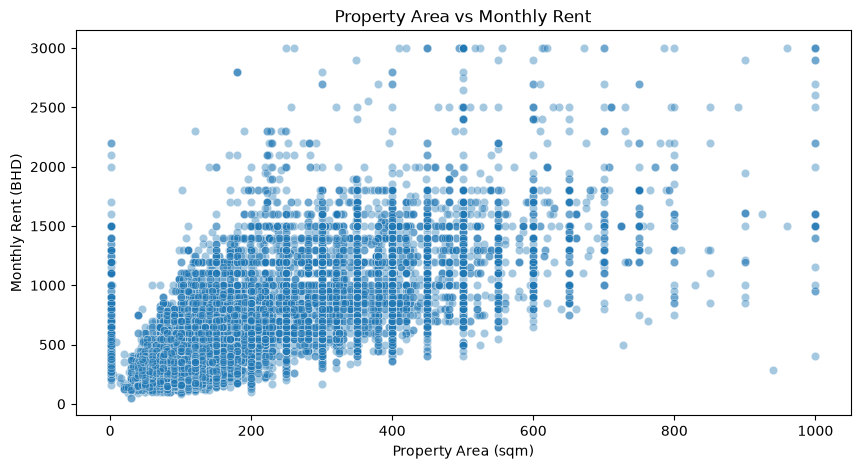

In [28]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean[
        (df_clean['area_sqm_num'] <= 1000) &
        (df_clean['rent'] <= 3000)
    ],
    x='area_sqm_num',
    y='rent',
    alpha=0.4
)

plt.title('Property Area vs Monthly Rent')
plt.xlabel('Property Area (sqm)')
plt.ylabel('Monthly Rent (BHD)')
plt.show()

In [29]:
df_clean['property_type'].value_counts(dropna=False)

property_type
Apartment                       25001
Villa                            6086
Compound                          350
Duplex                            292
Penthouse                         182
Townhouse                          51
Whole Building                     49
Hotel Apartment                    19
Bulk Rent Unit                     12
Short Term & Hotel Apartment        9
Bungalow                            3
Land                                3
Chalet                              2
Name: count, dtype: int64

In [30]:
df_clean['governorate'].value_counts(dropna=False).head(30)

governorate
Capital Governorate                        12840
Muharraq Governorate                        6218
Northern Governorate                        6064
Capital Governorate, Manama                 2251
Muharraq Governorate, Amwaj Islands         1536
Central Governorate                         1110
Muharraq Governorate, Diyar Al Muharraq      687
Southern Governorate                         539
Southern Governorate, Riffa                  357
Muharraq Governorate, Dilmunia Island        290
Capital Governorate, Hoora                   104
Northern Governorate, Bu Quwah                33
Southern Governorate, Durrat Al Bahrain       18
Southern Governorate, Zallaq                  12
Name: count, dtype: int64

In [31]:
df_clean['furnished'].value_counts(dropna=False)

furnished
NaN       17730
YES       10080
PARTLY     3336
NO          913
Name: count, dtype: int64

In [32]:
def clean_categories(data):
    data = data.copy()

    # Split governorate and neighborhood
    location_parts = data['governorate'].str.split(
        ',', n=1, expand=True
    )

    data['governorate_main'] = (
        location_parts[0].str.strip()
    )

    if 1 in location_parts.columns:
        data['neighborhood'] = (
            location_parts[1].str.strip()
            .fillna('Unknown')
        )
    else:
        data['neighborhood'] = 'Unknown'

    # Clean furnished
    data['furnished_clean'] = (
        data['furnished']
        .fillna('Unknown')
        .str.strip()
        .str.upper()
    )

    # Clean property type
    data['property_type_clean'] = (
        data['property_type']
        .fillna('Unknown')
        .str.strip()
    )

    return data


df_clean = clean_categories(df_clean)

In [33]:
df_clean[
    ['governorate', 'governorate_main',
     'neighborhood', 'furnished_clean',
     'property_type_clean']
].sample(10, random_state=42)

,governorate,governorate_main,neighborhood,furnished_clean,property_type_clean
8499,Capital Governorate,Capital Governorate,Unknown,YES,Apartment
26166,Muharraq Governorate,Muharraq Governorate,Unknown,UNKNOWN,Apartment
10121,Capital Governorate,Capital Governorate,Unknown,UNKNOWN,Apartment
24826,Capital Governorate,Capital Governorate,Unknown,UNKNOWN,Apartment
18680,Muharraq Governorate,Muharraq Governorate,Unknown,UNKNOWN,Apartment
27294,Muharraq Governorate,Muharraq Governorate,Unknown,UNKNOWN,Apartment
10082,Muharraq Governorate,Muharraq Governorate,Unknown,UNKNOWN,Villa
25839,Capital Governorate,Capital Governorate,Unknown,YES,Apartment
28962,"Capital Governorate, Manama",Capital Governorate,Manama,PARTLY,Villa
17712,Capital Governorate,Capital Governorate,Unknown,UNKNOWN,Apartment


In [34]:
# Check duplicate property IDs
print("Duplicate Property_id:",
      df_clean['Property_id'].duplicated().sum())

# Check duplicate secondary property IDs
print("Duplicate Property_id.1:",
      df_clean['Property_id.1'].duplicated().sum())

# Check identical property characteristics
duplicate_columns = [
    'property_type_clean',
    'governorate',
    'bedrooms_num',
    'bathrooms_num',
    'area_sqm_num',
    'rent'
]

print("Duplicate property characteristics:",
      df_clean.duplicated(
          subset=duplicate_columns
      ).sum())

Duplicate Property_id: 0
Duplicate Property_id.1: 0
Duplicate property characteristics: 15287


In [35]:
# Count repeated non-missing URLs
print(
    "Duplicate URLs:",
    df_clean['URL'].dropna().duplicated().sum()
)

Duplicate URLs: 565


In [36]:
duplicate_features = [
    'title',
    'property_type',
    'governorate',
    'bedrooms_num',
    'bathrooms_num',
    'area_sqm_num',
    'rent'
]

duplicates = df_clean[
    df_clean.duplicated(
        subset=duplicate_features,
        keep=False
    )
].sort_values(duplicate_features)

print("Rows in matching groups:", len(duplicates))

duplicates[
    ['Property_id', 'title', 'property_type',
     'governorate', 'area_sqm_num', 'rent']
].head(20)

Rows in matching groups: 6211


,Property_id,title,property_type,governorate,area_sqm_num,rent
5032,b5d34d07-89b7-4f77-bb29-3cd1fe55d865,! Semi Furnished ! 2 BR Apartment !,Apartment,Northern Governorate,135.0,230.0
24260,1e920b16-81f0-4745-a463-1a6c7e4c5f44,! Semi Furnished ! 2 BR Apartment !,Apartment,Northern Governorate,135.0,230.0
7165,2ab890e8-d137-4806-86b0-c6967924a1c7,$ BIG BALCONY | SEA VIEW | PREMIUM FURNITURE $,Apartment,Capital Governorate,140.0,750.0
7686,a70e4021-73a4-4b3b-93bd-26acff46dc27,$ BIG BALCONY | SEA VIEW | PREMIUM FURNITURE $,Apartment,Capital Governorate,140.0,750.0
22895,f33b0fe3-9f54-40bc-a2fa-250c879fd491,****140 BD 2BR Flat in salmabad***------------,Apartment,Central Governorate,80.0,140.0
27927,805dc9a1-039a-423c-959a-49645f940c08,****140 BD 2BR Flat in salmabad***------------,Apartment,Central Governorate,80.0,140.0
15972,593235a5-9921-489d-abf6-921cc930b544,**4BR - SPACIOUS - PVT POOL - GARDEN**,Villa,Northern Governorate,500.0,1500.0
26471,1a542950-afe1-427a-a7d2-732c651d2208,**4BR - SPACIOUS - PVT POOL - GARDEN**,Villa,Northern Governorate,500.0,1500.0
11920,997e7ea4-03c1-4432-bf58-485a25a3d2ce,**5BR - PRIVATE POOL- SEMI FURNISHED**,Villa,Northern Governorate,480.0,1200.0
18651,eae9da13-3015-47a3-888a-a4c99f8838ea,**5BR - PRIVATE POOL- SEMI FURNISHED**,Villa,Northern Governorate,480.0,1200.0


In [37]:
# Check whether training property IDs appear in test data
common_ids = set(df['Property_id'].dropna()) & set(
    test['Property_id'].dropna()
)

print("Matching Property IDs:", len(common_ids))

Matching Property IDs: 0


In [38]:
# Keep rows with valid URLs
url_data = df_clean.dropna(subset=['URL']).copy()

# Group by URL and examine rental prices
url_summary = url_data.groupby('URL').agg(
    listing_count=('rent', 'size'),
    unique_rents=('rent', 'nunique'),
    min_rent=('rent', 'min'),
    max_rent=('rent', 'max')
)

# Only repeated URLs
repeated_urls = url_summary[
    url_summary['listing_count'] > 1
]

print("Repeated URL groups:", len(repeated_urls))

print(
    "Repeated URLs with different rents:",
    (repeated_urls['unique_rents'] > 1).sum()
)

display(
    repeated_urls.sort_values(
        'listing_count', ascending=False
    ).head(15)
)

Repeated URL groups: 526
Repeated URLs with different rents: 66


,listing_count,unique_rents,min_rent,max_rent
URL,,,,
https://www.propertyfinder.bh/en/plp/rent/apartment-for-rent-capital-governorate-seef-957041.html,5,1,300.0,300.0
https://www.propertyfinder.bh/en/plp/rent/apartment-for-rent-capital-governorate-seef-957043.html,5,1,370.0,370.0
https://www.propertyfinder.bh/en/plp/rent/apartment-for-rent-muharraq-governorate-amwaj-islands-amwaj-marina-957062.html,4,1,400.0,400.0
https://www.propertyfinder.bh/en/plp/rent/apartment-for-rent-muharraq-governorate-diyar-al-muharraq-marassi-al-bahrain-957040.html,4,1,1300.0,1300.0
https://www.propertyfinder.bh/en/plp/rent/apartment-for-rent-northern-governorate-saar-957071.html,4,1,450.0,450.0
https://www.propertyfinder.bh/en/plp/rent/apartment-for-rent-muharraq-governorate-amwaj-islands-the-lagoon-956963.html,3,1,700.0,700.0
https://www.propertyfinder.bh/en/plp/rent/apartment-for-rent-muharraq-governorate-amwaj-islands-amwaj-avenue-956937.html,3,1,300.0,300.0
https://www.propertyfinder.bh/en/plp/rent/apartment-for-rent-muharraq-governorate-amwaj-islands-amwaj-avenue-956941.html,3,1,400.0,400.0
https://www.propertyfinder.bh/en/plp/rent/apartment-for-rent-capital-governorate-manama-sanabis-957063.html,3,1,250.0,250.0


In [39]:

numerical_features = [
    'bedrooms_num',
    'bathrooms_num',
    'area_sqm_num',
    'maid_room'
]

categorical_features = [
    'property_type_clean',
    'governorate_main',
    'neighborhood',
    'furnished_clean'
]

features = numerical_features + categorical_features

X = df_clean[features].copy()
y = df_clean['rent'].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (32059, 8)
y shape: (32059,)


In [40]:
from sklearn.model_selection import GroupShuffleSplit

# Group records with the same URL
groups = df_clean['URL'].copy()

# Give each missing URL its own group
missing_url = groups.isna()

groups.loc[missing_url] = (
    'missing_url_' +
    df_clean.index[missing_url].astype(str)
)

# Split: 80% training, 20% validation
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (25661, 8)
Validation: (6398, 8)


In [41]:
train_groups = set(groups.iloc[train_idx])
val_groups = set(groups.iloc[val_idx])

print(
    "Overlapping groups:",
    len(train_groups.intersection(val_groups))
)

print("Training mean rent:", y_train.mean())
print("Validation mean rent:", y_val.mean())
print("Training median rent:", y_train.median())
print("Validation median rent:", y_val.median())

Overlapping groups: 0
Training mean rent: 581.570320720159
Validation mean rent: 576.5700218818381
Training median rent: 450.0
Validation median rent: 450.0


In [42]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [43]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    )),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [44]:
# Build the model pipeline
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
y_train_pred = lr_model.predict(X_train)
y_val_pred = lr_model.predict(X_val)

In [45]:
# Calculate evaluation metrics
train_mae = mean_absolute_error(y_train, y_train_pred)
val_mae = mean_absolute_error(y_val, y_val_pred)

train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred)
)

val_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred)
)

train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)

print("Linear Regression Results")
print("-" * 35)

print(f"Training MAE: {train_mae:.2f} BHD")
print(f"Validation MAE: {val_mae:.2f} BHD")

print(f"Training RMSE: {train_rmse:.2f}")
print(f"Validation RMSE: {val_rmse:.2f}")

print(f"Training R²: {train_r2:.4f}")
print(f"Validation R²: {val_r2:.4f}")

Linear Regression Results
-----------------------------------
Training MAE: 152.17 BHD
Validation MAE: 151.46 BHD
Training RMSE: 242.21
Validation RMSE: 240.79
Training R²: 0.6431
Validation R²: 0.6272


In [46]:
from sklearn.ensemble import RandomForestRegressor

In [47]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

In [48]:
rf_model.fit(X_train, y_train)

rf_train_pred = rf_model.predict(X_train)
rf_val_pred = rf_model.predict(X_val)

In [49]:
rf_train_mae = mean_absolute_error(
    y_train, rf_train_pred
)

rf_val_mae = mean_absolute_error(
    y_val, rf_val_pred
)

rf_train_rmse = np.sqrt(
    mean_squared_error(y_train, rf_train_pred)
)

rf_val_rmse = np.sqrt(
    mean_squared_error(y_val, rf_val_pred)
)

rf_train_r2 = r2_score(y_train, rf_train_pred)
rf_val_r2 = r2_score(y_val, rf_val_pred)

print("Random Forest Results")
print("-" * 35)

print(f"Training MAE: {rf_train_mae:.2f} BHD")
print(f"Validation MAE: {rf_val_mae:.2f} BHD")

print(f"Training RMSE: {rf_train_rmse:.2f}")
print(f"Validation RMSE: {rf_val_rmse:.2f}")

print(f"Training R²: {rf_train_r2:.4f}")
print(f"Validation R²: {rf_val_r2:.4f}")

Random Forest Results
-----------------------------------
Training MAE: 111.99 BHD
Validation MAE: 128.69 BHD
Training RMSE: 180.47
Validation RMSE: 214.54
Training R²: 0.8019
Validation R²: 0.7041


In [50]:
from catboost import CatBoostRegressor

In [51]:
X_train_cb = X_train.copy()
X_val_cb = X_val.copy()

# Fill missing numerical values
for col in numerical_features:
    median_value = X_train_cb[col].median()

    X_train_cb[col] = X_train_cb[col].fillna(
        median_value
    )

    X_val_cb[col] = X_val_cb[col].fillna(
        median_value
    )

# Fill missing categorical values
for col in categorical_features:
    X_train_cb[col] = (
        X_train_cb[col].fillna('Unknown').astype(str)
    )

    X_val_cb[col] = (
        X_val_cb[col].fillna('Unknown').astype(str)
    )

In [52]:
cb_model = CatBoostRegressor(
    iterations=1500,
    depth=6,
    learning_rate=0.05,
    loss_function='MAE',
    eval_metric='MAE',
    random_seed=42,
    verbose=200
)

cb_model.fit(
    X_train_cb,
    y_train,
    cat_features=categorical_features,
    eval_set=(X_val_cb, y_val),
    early_stopping_rounds=100
)

0:	learn: 252.6065107	test: 244.3835719	best: 244.3835719 (0)	total: 211ms	remaining: 5m 16s
200:	learn: 133.8740455	test: 134.1735872	best: 134.1735872 (200)	total: 10.7s	remaining: 1m 9s
400:	learn: 128.4474169	test: 130.6942366	best: 130.6942366 (400)	total: 21.4s	remaining: 58.6s
600:	learn: 125.9548718	test: 129.1961500	best: 129.1961500 (600)	total: 31.9s	remaining: 47.8s
800:	learn: 124.3942228	test: 128.2660064	best: 128.2660064 (800)	total: 41.3s	remaining: 36s
1000:	learn: 123.0346878	test: 127.6099728	best: 127.6098379 (998)	total: 50.8s	remaining: 25.3s
1200:	learn: 122.0767561	test: 127.2353943	best: 127.2353943 (1200)	total: 1m	remaining: 14.9s
1400:	learn: 121.2473926	test: 126.9171051	best: 126.9171051 (1400)	total: 1m 9s	remaining: 4.88s
1499:	learn: 121.0055032	test: 126.7841044	best: 126.7840191 (1498)	total: 1m 14s	remaining: 0us

bestTest = 126.7840191
bestIteration = 1498

Shrink model to first 1499 iterations.


CatBoostRegressor(depth=6, eval_metric='MAE', iterations=1500, learning_rate=0.05, loss_function='MAE', random_seed=42, verbose=200)

In [53]:
cb_train_pred = cb_model.predict(X_train_cb)
cb_val_pred = cb_model.predict(X_val_cb)

cb_train_mae = mean_absolute_error(
    y_train, cb_train_pred
)

cb_val_mae = mean_absolute_error(
    y_val, cb_val_pred
)

cb_train_rmse = np.sqrt(
    mean_squared_error(y_train, cb_train_pred)
)

cb_val_rmse = np.sqrt(
    mean_squared_error(y_val, cb_val_pred)
)

cb_train_r2 = r2_score(y_train, cb_train_pred)
cb_val_r2 = r2_score(y_val, cb_val_pred)

print("CatBoost Results")
print("-" * 35)

print(f"Training MAE: {cb_train_mae:.2f} BHD")
print(f"Validation MAE: {cb_val_mae:.2f} BHD")

print(f"Training RMSE: {cb_train_rmse:.2f}")
print(f"Validation RMSE: {cb_val_rmse:.2f}")

print(f"Training R²: {cb_train_r2:.4f}")
print(f"Validation R²: {cb_val_r2:.4f}")

print("Best iteration:", cb_model.best_iteration_)

CatBoost Results
-----------------------------------
Training MAE: 122.71 BHD
Validation MAE: 126.78 BHD
Training RMSE: 209.82
Validation RMSE: 222.32
Training R²: 0.7322
Validation R²: 0.6822
Best iteration: 1498


In [54]:
# Extract feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train_cb.columns,
    'Importance': cb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Feature,Importance
2,area_sqm_num,34.833407
1,bathrooms_num,20.730260
5,governorate_main,11.249714
0,bedrooms_num,9.431243
7,furnished_clean,8.416179
4,property_type_clean,7.762637
6,neighborhood,5.914281
3,maid_room,1.662280


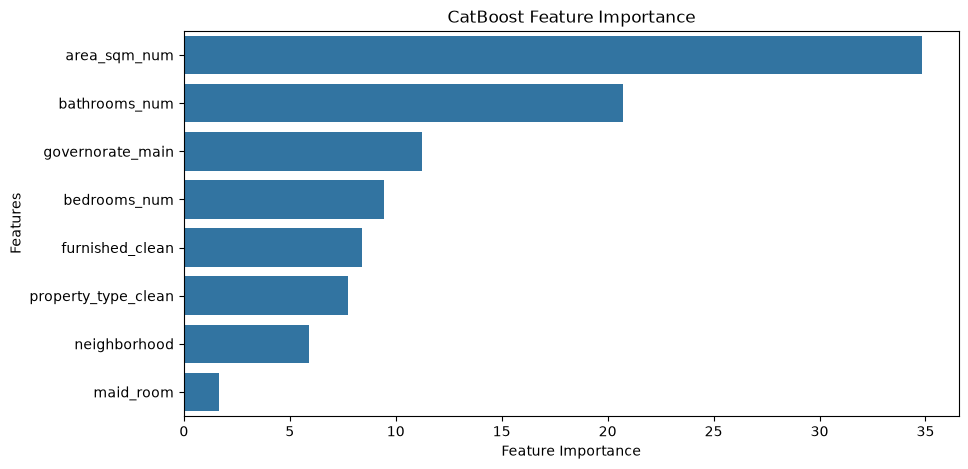

In [55]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('CatBoost Feature Importance')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.show()

In [56]:
location_features = [
    'city',
    'location',
    'location_full',
    'latitude',
    'longitude'
]

df_clean[location_features].isnull().sum()

city             23853
location         29160
location_full    17717
latitude         17717
longitude        17717
dtype: int64

In [57]:
df_clean['city'].value_counts(dropna=False).head(20)

city
NaN                  23853
Al Juffair            1370
Manama                1368
Amwaj Islands          989
Saar                   699
Seef                   629
Janabiya               488
Hidd                   459
Diyar Al Muharraq      257
Busaiteen              244
Reef Island            232
Dilmunia Island        210
Hamala                 191
Riffa                  157
Tubli                  137
Budaiya                 91
Al Jasra                79
Galali                  57
Arad                    55
Barbar                  47
Name: count, dtype: int64

In [58]:
df_clean['location'].value_counts(dropna=False).head(20)

location
NaN                          29160
Amwaj Avenue                   400
Adliya                         267
The Lagoon                     220
Mahooz                         213
Um Al Hasam                    175
Zinj                           152
Amwaj Marina                   124
Sanabis                        109
Al Burhama                      93
Bahrain Financial Harbour       90
Tala Island                     86
Marassi Al Bahrain              86
Marassi Residences              63
Al Marsa Floating City          58
Essence of Dilmunia             57
The Treasure                    51
Salmaniya                       46
Segaya                          43
Abraj Al Lulu                   41
Name: count, dtype: int64

In [59]:
df_clean[
    ['governorate', 'city', 'location',
     'location_full', 'latitude', 'longitude']
].sample(20, random_state=42)

,governorate,city,location,location_full,latitude,longitude
8499,Capital Governorate,NaN,NaN,"Reef Island, Capital Governorate",26.241751,50.566395
26166,Muharraq Governorate,NaN,NaN,NaN,NaN,NaN
10121,Capital Governorate,NaN,NaN,NaN,NaN,NaN
24826,Capital Governorate,NaN,NaN,NaN,NaN,NaN
18680,Muharraq Governorate,Hidd,NaN,NaN,NaN,NaN
27294,Muharraq Governorate,Dilmunia Island,Hanging Garden,NaN,NaN,NaN
10082,Muharraq Governorate,Galali,NaN,NaN,NaN,NaN
25839,Capital Governorate,NaN,NaN,"Hoora, Capital Governorate",26.233879,50.593983
28962,"Capital Governorate, Manama",NaN,NaN,"Karbabad, Manama, Capital Governorate",26.233418,50.533192
17712,Capital Governorate,NaN,NaN,NaN,NaN,NaN


In [60]:
# Create new location features
df_clean['city_clean'] = (
    df_clean['city']
    .fillna('Unknown')
    .str.strip()
)

df_clean['location_clean'] = (
    df_clean['location']
    .fillna('Unknown')
    .str.strip()
)

df_clean['location_full_clean'] = (
    df_clean['location_full']
    .fillna('Unknown')
    .str.strip()
)

# Ensure coordinates are numeric
df_clean['latitude'] = pd.to_numeric(
    df_clean['latitude'], errors='coerce'
)

df_clean['longitude'] = pd.to_numeric(
    df_clean['longitude'], errors='coerce'
)

In [61]:
new_categorical_features = categorical_features + [
    'city_clean',
    'location_clean',
    'location_full_clean'
]

new_numerical_features = numerical_features + [
    'latitude',
    'longitude'
]

features_v2 = (
    new_numerical_features +
    new_categorical_features
)

X_v2 = df_clean[features_v2].copy()

print("Features:", len(features_v2))
print("Dataset shape:", X_v2.shape)

Features: 13
Dataset shape: (32059, 13)


In [62]:
X_train_v2 = X_v2.iloc[train_idx].copy()
X_val_v2 = X_v2.iloc[val_idx].copy()

# Fill missing numerical values
# CatBoost can handle NaN in numerical features
for col in new_numerical_features:
    X_train_v2[col] = pd.to_numeric(
        X_train_v2[col], errors='coerce'
    )
    X_val_v2[col] = pd.to_numeric(
        X_val_v2[col], errors='coerce'
    )

# Fill missing categorical values
for col in new_categorical_features:
    X_train_v2[col] = (
        X_train_v2[col].fillna('Unknown').astype(str)
    )
    X_val_v2[col] = (
        X_val_v2[col].fillna('Unknown').astype(str)
    )

print("Training:", X_train_v2.shape)
print("Validation:", X_val_v2.shape)

Training: (25661, 13)
Validation: (6398, 13)


In [63]:
cb_model_v2 = CatBoostRegressor(
    iterations=1500,
    depth=6,
    learning_rate=0.05,
    loss_function='MAE',
    eval_metric='MAE',
    random_seed=42,
    verbose=200
)

cb_model_v2.fit(
    X_train_v2,
    y_train,
    cat_features=new_categorical_features,
    eval_set=(X_val_v2, y_val),
    early_stopping_rounds=100
)

0:	learn: 252.9188738	test: 244.8347910	best: 244.8347910 (0)	total: 95.4ms	remaining: 2m 23s
200:	learn: 125.1586947	test: 124.3289181	best: 124.3289181 (200)	total: 12s	remaining: 1m 17s
400:	learn: 118.5839607	test: 120.1508524	best: 120.1508524 (400)	total: 23.8s	remaining: 1m 5s
600:	learn: 115.5706941	test: 118.6623592	best: 118.6623592 (600)	total: 35.3s	remaining: 52.8s
800:	learn: 113.7991936	test: 118.0490492	best: 118.0490492 (800)	total: 46.9s	remaining: 40.9s
1000:	learn: 112.0600866	test: 117.2644860	best: 117.2644860 (1000)	total: 58.2s	remaining: 29s
1200:	learn: 110.8630655	test: 116.7491476	best: 116.7491476 (1200)	total: 1m 9s	remaining: 17.4s
1400:	learn: 109.9847890	test: 116.4912409	best: 116.4519105 (1398)	total: 1m 22s	remaining: 5.84s
1499:	learn: 109.5100089	test: 116.3061239	best: 116.3047630 (1498)	total: 1m 29s	remaining: 0us

bestTest = 116.304763
bestIteration = 1498

Shrink model to first 1499 iterations.


CatBoostRegressor(depth=6, eval_metric='MAE', iterations=1500, learning_rate=0.05, loss_function='MAE', random_seed=42, verbose=200)

In [64]:
cb_v2_train_pred = cb_model_v2.predict(X_train_v2)
cb_v2_val_pred = cb_model_v2.predict(X_val_v2)

cb_v2_train_mae = mean_absolute_error(
    y_train, cb_v2_train_pred
)

cb_v2_val_mae = mean_absolute_error(
    y_val, cb_v2_val_pred
)

cb_v2_val_rmse = np.sqrt(
    mean_squared_error(y_val, cb_v2_val_pred)
)

cb_v2_val_r2 = r2_score(
    y_val, cb_v2_val_pred
)

print("CatBoost Version 2 Results")
print("-" * 40)

print(f"Training MAE: {cb_v2_train_mae:.2f} BHD")
print(f"Validation MAE: {cb_v2_val_mae:.2f} BHD")
print(f"Validation RMSE: {cb_v2_val_rmse:.2f}")
print(f"Validation R²: {cb_v2_val_r2:.4f}")
print("Best iteration:", cb_model_v2.best_iteration_)

print("-" * 40)
print(
    f"MAE improvement: "
    f"{cb_val_mae - cb_v2_val_mae:.2f} BHD"
)

CatBoost Version 2 Results
----------------------------------------
Training MAE: 111.16 BHD
Validation MAE: 116.30 BHD
Validation RMSE: 215.14
Validation R²: 0.7024
Best iteration: 1498
----------------------------------------
MAE improvement: 10.48 BHD


In [65]:
feature_importance_v2 = pd.DataFrame({
    'Feature': X_train_v2.columns,
    'Importance': cb_model_v2.feature_importances_
})

feature_importance_v2 = feature_importance_v2.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance_v2)

,Feature,Importance
2,area_sqm_num,25.177011
1,bathrooms_num,19.829663
6,property_type_clean,11.054503
7,governorate_main,8.404295
0,bedrooms_num,7.320593
4,latitude,6.095791
12,location_full_clean,6.018619
9,furnished_clean,5.281966
5,longitude,3.334394
10,city_clean,3.066273


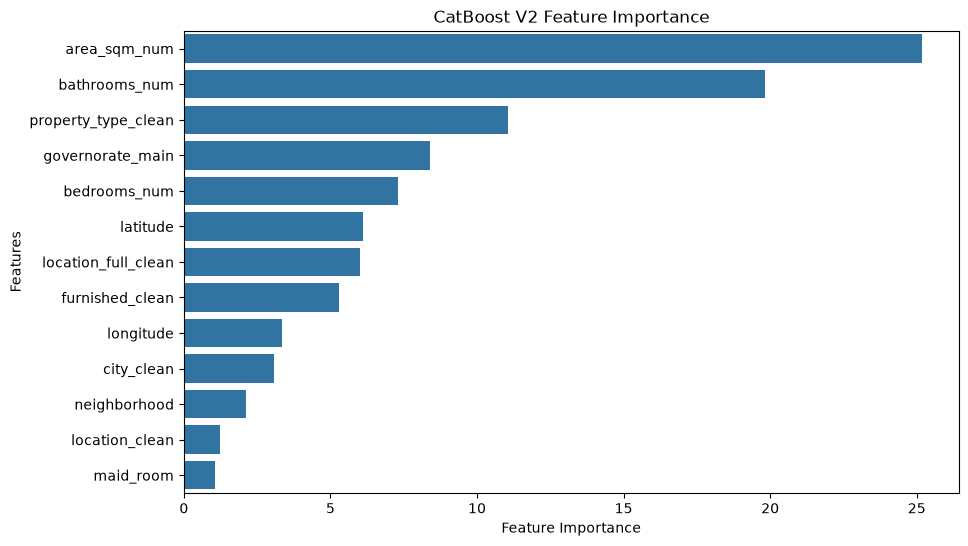

In [66]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_v2,
    x='Importance',
    y='Feature'
)

plt.title('CatBoost V2 Feature Importance')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.show()

In [67]:
columns_to_check = [
    'amenities',
    'include_w_e',
    'period',
    'is_featured',
    'is_premium'
]

df_clean[columns_to_check].isnull().sum()

amenities       8523
include_w_e     8206
period         17717
is_featured    17717
is_premium     17717
dtype: int64

In [68]:
# Display examples of amenities
df_clean['amenities'].dropna().sample(
    15, random_state=42
)

17646    Central A/C, Covered Parking, Kitchen Applianc...
24254                                                  7.0
12166    Barbecue Area, Built in Wardrobes, Covered Par...
1258                                                   7.0
20710    Built in Wardrobes, Central A/C, Kitchen Appli...
19204    Balcony, Barbecue Area, Built in Wardrobes, Ce...
23577                       Balcony, Central A/C, Security
8822                                                   9.0
13889                                                  9.0
11233                                                 16.0
18318    Balcony, Barbecue Area, Built in Wardrobes, Ce...
5657     Balcony, Central A/C, Covered Parking, Kitchen...
15418                                                 15.0
19750                                                 14.0
16842                                                 10.0
Name: amenities, dtype: str

In [69]:
df_clean['include_w_e'].value_counts(
    dropna=False
)

include_w_e
inclusive      9443
NaN            8206
Inclusive      5833
notSelected    4798
Exclusive      3678
exclusive       101
Name: count, dtype: int64

In [70]:
df_clean['period'].value_counts(
    dropna=False
)

period
NaN        17717
monthly    14342
Name: count, dtype: int64

In [71]:
df_clean['include_w_e_clean'] = (
    df_clean['include_w_e']
    .fillna('unknown')
    .astype(str)
    .str.strip()
    .str.lower()
)

df_clean['include_w_e_clean'].value_counts()

include_w_e_clean
inclusive      15276
unknown         8206
notselected     4798
exclusive       3779
Name: count, dtype: int64

In [72]:
# Amenities to extract
amenity_keywords = {
    'has_pool': r'\b(?:shared|private)\s+pool\b',
    'has_gym': r'\b(?:shared|private)\s+gym\b',
    'has_parking': r'\b(?:covered\s+)?parking\b',
    'has_balcony': r'\bbalcony\b',
    'has_security': r'\bsecurity\b',
    'has_sea_view': r'\bview of water\b',
    'has_ac': r'\bcentral a/c\b',
    'has_kitchen_appliances': r'\bkitchen appliances\b',
    'has_garden': r'\b(?:private|shared)\s+garden\b',
    'has_maid_service': r'\bmaid service\b'
}

# Identify text-based amenity records
amenities_text = df_clean['amenities'].fillna('').astype(str)

numeric_only = amenities_text.str.fullmatch(
    r'\s*\d+(\.\d+)?\s*'
)

has_text = (
    amenities_text.str.strip().ne('') &
    ~numeric_only
)

df_clean['amenities_text_available'] = has_text.astype(int)

# Extract individual amenities
for feature, pattern in amenity_keywords.items():
    df_clean[feature] = (
        amenities_text.str.contains(
            pattern,
            case=False,
            regex=True,
            na=False
        ) & has_text
    ).astype(int)

# Count explicitly listed amenities
df_clean['amenities_count'] = (
    amenities_text
    .where(has_text, '')
    .str.split(',')
    .apply(lambda x: len(x) if x != [''] else 0)
)

In [73]:
amenity_features = list(amenity_keywords.keys())

print("Amenity feature counts:")
print(df_clean[amenity_features].sum().sort_values(
    ascending=False
))

print("\nAmenity count statistics:")
print(df_clean['amenities_count'].describe())

print("\nText-based amenity records:")
print(df_clean['amenities_text_available'].value_counts())

Amenity feature counts:
has_parking               12829
has_security              12009
has_kitchen_appliances    10954
has_ac                    10820
has_pool                   9939
has_gym                    9061
has_balcony                8601
has_sea_view               4968
has_garden                 2170
has_maid_service           1973
dtype: int64

Amenity count statistics:
count    32059.000000
mean         4.685517
std          6.310106
min          0.000000
25%          0.000000
50%          0.000000
75%         10.000000
max         25.000000
Name: amenities_count, dtype: float64

Text-based amenity records:
amenities_text_available
0    17760
1    14299
Name: count, dtype: int64


In [74]:
df_clean[
    [
        'amenities',
        'amenities_count',
        'has_pool',
        'has_gym',
        'has_parking',
        'has_sea_view',
        'include_w_e_clean'
    ]
].sample(15, random_state=42)

,amenities,amenities_count,has_pool,has_gym,has_parking,has_sea_view,include_w_e_clean
8499,"Balcony, Barbecue Area, Built in Wardrobes, Ce...",13,1,1,1,0,inclusive
26166,1.0,0,0,0,0,0,exclusive
10121,12.0,0,0,0,0,0,inclusive
24826,14.0,0,0,0,0,0,inclusive
18680,NaN,0,0,0,0,0,unknown
27294,NaN,0,0,0,0,0,unknown
10082,NaN,0,0,0,0,0,unknown
25839,"Balcony, Barbecue Area, Built in Wardrobes, Ce...",16,1,1,1,0,inclusive
28962,"Central A/C, Covered Parking, Maids Room, Secu...",4,0,0,1,0,inclusive
17712,14.0,0,0,0,0,0,inclusive


In [75]:
# Additional numerical features
extra_numerical_features = amenity_features + [
    'amenities_count',
    'amenities_text_available'
]

# Additional categorical features
extra_categorical_features = [
    'include_w_e_clean'
]

# Combine V2 and new features
numerical_features_v3 = (
    new_numerical_features +
    extra_numerical_features
)

categorical_features_v3 = (
    new_categorical_features +
    extra_categorical_features
)

features_v3 = (
    numerical_features_v3 +
    categorical_features_v3
)

X_v3 = df_clean[features_v3].copy()

print("Total features:", len(features_v3))
print("Dataset shape:", X_v3.shape)

Total features: 26
Dataset shape: (32059, 26)


In [76]:
X_train_v3 = X_v3.iloc[train_idx].copy()
X_val_v3 = X_v3.iloc[val_idx].copy()

# Numerical columns
for col in numerical_features_v3:
    X_train_v3[col] = pd.to_numeric(
        X_train_v3[col], errors='coerce'
    )

    X_val_v3[col] = pd.to_numeric(
        X_val_v3[col], errors='coerce'
    )

# Categorical columns
for col in categorical_features_v3:
    X_train_v3[col] = (
        X_train_v3[col]
        .fillna('Unknown')
        .astype(str)
    )

    X_val_v3[col] = (
        X_val_v3[col]
        .fillna('Unknown')
        .astype(str)
    )

print("Training:", X_train_v3.shape)
print("Validation:", X_val_v3.shape)

Training: (25661, 26)
Validation: (6398, 26)


In [77]:
cb_model_v3 = CatBoostRegressor(
    iterations=1500,
    depth=6,
    learning_rate=0.05,
    loss_function='MAE',
    eval_metric='MAE',
    random_seed=42,
    verbose=200
)

cb_model_v3.fit(
    X_train_v3,
    y_train,
    cat_features=categorical_features_v3,
    eval_set=(X_val_v3, y_val),
    early_stopping_rounds=100
)

0:	learn: 252.7710328	test: 244.6871277	best: 244.6871277 (0)	total: 101ms	remaining: 2m 31s
200:	learn: 122.8603825	test: 121.8488721	best: 121.8488721 (200)	total: 14.5s	remaining: 1m 33s
400:	learn: 115.8506160	test: 117.5498245	best: 117.5498245 (400)	total: 28.5s	remaining: 1m 18s
600:	learn: 112.5249039	test: 116.0593345	best: 116.0593345 (600)	total: 42.8s	remaining: 1m 4s
800:	learn: 110.5926499	test: 115.1899167	best: 115.1802001 (795)	total: 56.7s	remaining: 49.5s
1000:	learn: 108.8831285	test: 114.4528822	best: 114.4528822 (1000)	total: 1m 10s	remaining: 35.3s
1200:	learn: 107.7721321	test: 114.0435112	best: 114.0435112 (1200)	total: 1m 25s	remaining: 21.3s
1400:	learn: 106.7676836	test: 113.7255698	best: 113.7255698 (1400)	total: 1m 39s	remaining: 7.03s
1499:	learn: 106.3354052	test: 113.5863829	best: 113.5863829 (1499)	total: 1m 45s	remaining: 0us

bestTest = 113.5863829
bestIteration = 1499



CatBoostRegressor(depth=6, eval_metric='MAE', iterations=1500, learning_rate=0.05, loss_function='MAE', random_seed=42, verbose=200)

In [78]:
cb_v3_train_pred = cb_model_v3.predict(X_train_v3)
cb_v3_val_pred = cb_model_v3.predict(X_val_v3)

cb_v3_train_mae = mean_absolute_error(
    y_train, cb_v3_train_pred
)

cb_v3_val_mae = mean_absolute_error(
    y_val, cb_v3_val_pred
)

cb_v3_val_rmse = np.sqrt(
    mean_squared_error(y_val, cb_v3_val_pred)
)

cb_v3_val_r2 = r2_score(
    y_val, cb_v3_val_pred
)

print("CatBoost Version 3 Results")
print("-" * 40)

print(f"Training MAE: {cb_v3_train_mae:.2f} BHD")
print(f"Validation MAE: {cb_v3_val_mae:.2f} BHD")
print(f"Validation RMSE: {cb_v3_val_rmse:.2f}")
print(f"Validation R²: {cb_v3_val_r2:.4f}")
print("Best iteration:", cb_model_v3.best_iteration_)

print("-" * 40)

print(
    f"MAE improvement over V2: "
    f"{cb_v2_val_mae - cb_v3_val_mae:.2f} BHD"
)

CatBoost Version 3 Results
----------------------------------------
Training MAE: 107.79 BHD
Validation MAE: 113.59 BHD
Validation RMSE: 213.48
Validation R²: 0.7070
Best iteration: 1499
----------------------------------------
MAE improvement over V2: 2.72 BHD


In [79]:
experiments = [
    {'depth': 5, 'learning_rate': 0.05, 'iterations': 2500},
    {'depth': 6, 'learning_rate': 0.05, 'iterations': 2500},
    {'depth': 7, 'learning_rate': 0.05, 'iterations': 2500},
    {'depth': 8, 'learning_rate': 0.03, 'iterations': 3000}
]

In [80]:
results_v4 = []
models_v4 = []

for i, params in enumerate(experiments, start=1):

    model = CatBoostRegressor(
        **params,
        loss_function='MAE',
        eval_metric='MAE',
        random_seed=42,
        verbose=False,
        thread_count=-1
    )

    model.fit(
        X_train_v3,
        y_train,
        cat_features=categorical_features_v3,
        eval_set=(X_val_v3, y_val),
        early_stopping_rounds=150
    )

    train_pred = model.predict(X_train_v3)
    val_pred = model.predict(X_val_v3)

    train_mae = mean_absolute_error(
        y_train, train_pred
    )

    val_mae = mean_absolute_error(
        y_val, val_pred
    )

    results_v4.append({
        'Experiment': i,
        'Depth': params['depth'],
        'Learning Rate': params['learning_rate'],
        'Max Iterations': params['iterations'],
        'Best Iteration': model.best_iteration_,
        'Train MAE': round(train_mae, 2),
        'Validation MAE': round(val_mae, 2)
    })

    models_v4.append(model)

    print(
        f"Experiment {i}: "
        f"Train MAE = {train_mae:.2f}, "
        f"Validation MAE = {val_mae:.2f}"
    )

Experiment 1: Train MAE = 107.90, Validation MAE = 113.67
Experiment 2: Train MAE = 105.37, Validation MAE = 112.71
Experiment 3: Train MAE = 102.22, Validation MAE = 112.28
Experiment 4: Train MAE = 100.81, Validation MAE = 112.09


In [81]:
results_df_v4 = pd.DataFrame(results_v4)

results_df_v4 = results_df_v4.sort_values(
    'Validation MAE'
)

display(results_df_v4)

best_experiment = int(
    results_df_v4.iloc[0]['Experiment']
)

best_model_v4 = models_v4[best_experiment - 1]

print("Best experiment:", best_experiment)
print(
    "Best Validation MAE:",
    results_df_v4.iloc[0]['Validation MAE']
)

,Experiment,Depth,Learning Rate,Max Iterations,Best Iteration,Train MAE,Validation MAE
3,4,8,0.03,3000,2999,100.81,112.09
2,3,7,0.05,2500,2499,102.22,112.28
1,2,6,0.05,2500,2489,105.37,112.71
0,1,5,0.05,2500,2449,107.90,113.67


Best experiment: 4
Best Validation MAE: 112.09


In [82]:
from sklearn.model_selection import GroupKFold

gkf = GroupKFold(n_splits=5)

print("Number of folds:", gkf.get_n_splits())

Number of folds: 5


In [83]:
print("Best model parameters:")
print(best_model_v4.get_params())

print("\nBest iteration:")
print(best_model_v4.best_iteration_)

print("\nTraining MAE:")
print(
    mean_absolute_error(
        y_train,
        best_model_v4.predict(X_train_v3)
    )
)

print("\nValidation MAE:")
print(
    mean_absolute_error(
        y_val,
        best_model_v4.predict(X_val_v3)
    )
)

Best model parameters:
{'iterations': 3000, 'learning_rate': 0.03, 'depth': 8, 'loss_function': 'MAE', 'random_seed': 42, 'verbose': False, 'eval_metric': 'MAE'}

Best iteration:
2999

Training MAE:
100.80553744131151

Validation MAE:
112.08593043695097


In [84]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error
from catboost import CatBoostRegressor
import numpy as np
import pandas as pd

# Prepare full feature dataset
X_cv = df_clean[features_v3].copy()
y_cv = df_clean['rent'].copy()

# Numerical features
for col in numerical_features_v3:
    X_cv[col] = pd.to_numeric(
        X_cv[col], errors='coerce'
    )

# Categorical features
for col in categorical_features_v3:
    X_cv[col] = (
        X_cv[col]
        .fillna('Unknown')
        .astype(str)
    )

# Group repeated URLs together
groups_cv = df_clean['URL'].copy()

missing_url = (
    groups_cv.isna() |
    groups_cv.astype('string').str.strip().eq('').fillna(False)
)

groups_cv.loc[missing_url] = (
    'missing_url_' +
    df_clean.index[missing_url].astype(str)
)

print("Dataset:", X_cv.shape)
print("Unique groups:", groups_cv.nunique())

Dataset: (32059, 26)
Unique groups: 31494


In [85]:
gkf = GroupKFold(n_splits=5)

cv_results = []
cv_models = []

for fold, (train_index, val_index) in enumerate(
    gkf.split(X_cv, y_cv, groups_cv), start=1
):

    X_train_fold = X_cv.iloc[train_index]
    X_val_fold = X_cv.iloc[val_index]

    y_train_fold = y_cv.iloc[train_index]
    y_val_fold = y_cv.iloc[val_index]

    model = CatBoostRegressor(
        iterations=3000,
        depth=8,
        learning_rate=0.03,
        loss_function='MAE',
        eval_metric='MAE',
        random_seed=42,
        verbose=False,
        thread_count=-1
    )

    model.fit(
        X_train_fold,
        y_train_fold,
        cat_features=categorical_features_v3
    )

    predictions = model.predict(X_val_fold)

    fold_mae = mean_absolute_error(
        y_val_fold,
        predictions
    )

    cv_results.append({
        'Fold': fold,
        'MAE': fold_mae
    })

    cv_models.append(model)

    print(f"Fold {fold} MAE: {fold_mae:.2f} BHD")

Fold 1 MAE: 112.80 BHD
Fold 2 MAE: 113.22 BHD
Fold 3 MAE: 111.19 BHD
Fold 4 MAE: 116.00 BHD
Fold 5 MAE: 112.25 BHD


In [86]:
cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df)

print("-" * 40)

print(
    f"Mean CV MAE: "
    f"{cv_results_df['MAE'].mean():.2f} BHD"
)

print(
    f"Standard Deviation: "
    f"{cv_results_df['MAE'].std():.2f} BHD"
)

print(
    f"Best Fold MAE: "
    f"{cv_results_df['MAE'].min():.2f} BHD"
)

print(
    f"Worst Fold MAE: "
    f"{cv_results_df['MAE'].max():.2f} BHD"
)

,Fold,MAE
0,1,112.801052
1,2,113.223768
2,3,111.192180
3,4,116.001305
4,5,112.245343


----------------------------------------
Mean CV MAE: 113.09 BHD
Standard Deviation: 1.80 BHD
Best Fold MAE: 111.19 BHD
Worst Fold MAE: 116.00 BHD


In [87]:
from xgboost import XGBRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [88]:
numeric_transformer_xgb = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer_xgb = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

preprocessor_xgb = ColumnTransformer([
    ('num', numeric_transformer_xgb,
     numerical_features_v3),

    ('cat', categorical_transformer_xgb,
     categorical_features_v3)
])

In [89]:
xgb_model = Pipeline([
    ('preprocessor', preprocessor_xgb),

    ('model', XGBRegressor(
        n_estimators=2000,
        max_depth=6,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:absoluteerror',
        tree_method='hist',
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train_v3, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['bedrooms_num','bathrooms_num','area_sqm_num',...,'location_clean', 'location_full_clean','include_w_e_clean']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automaticall

In [90]:
xgb_train_pred = xgb_model.predict(X_train_v3)
xgb_val_pred = xgb_model.predict(X_val_v3)

xgb_train_mae = mean_absolute_error(
    y_train, xgb_train_pred
)

xgb_val_mae = mean_absolute_error(
    y_val, xgb_val_pred
)

xgb_val_rmse = np.sqrt(
    mean_squared_error(y_val, xgb_val_pred)
)

xgb_val_r2 = r2_score(
    y_val, xgb_val_pred
)

print("XGBoost Results")
print("-" * 40)

print(f"Training MAE: {xgb_train_mae:.2f} BHD")
print(f"Validation MAE: {xgb_val_mae:.2f} BHD")
print(f"Validation RMSE: {xgb_val_rmse:.2f}")
print(f"Validation R²: {xgb_val_r2:.4f}")

print("-" * 40)

print(
    f"Difference from CatBoost V4: "
    f"{112.08593043695097 - xgb_val_mae:.2f} BHD"
)

XGBoost Results
----------------------------------------
Training MAE: 97.78 BHD
Validation MAE: 109.25 BHD
Validation RMSE: 200.46
Validation R²: 0.7417
----------------------------------------
Difference from CatBoost V4: 2.84 BHD


In [91]:
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [92]:
lgbm_model = Pipeline([
    ('preprocessor', preprocessor_xgb),

    ('model', LGBMRegressor(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        objective='regression_l1',
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

In [93]:
lgbm_model.fit(X_train_v3, y_train)

lgbm_train_pred = lgbm_model.predict(X_train_v3)
lgbm_val_pred = lgbm_model.predict(X_val_v3)

In [94]:
lgbm_train_mae = mean_absolute_error(
    y_train, lgbm_train_pred
)

lgbm_val_mae = mean_absolute_error(
    y_val, lgbm_val_pred
)

lgbm_val_rmse = np.sqrt(
    mean_squared_error(y_val, lgbm_val_pred)
)

lgbm_val_r2 = r2_score(
    y_val, lgbm_val_pred
)

print("LightGBM Results")
print("-" * 40)

print(f"Training MAE: {lgbm_train_mae:.2f} BHD")
print(f"Validation MAE: {lgbm_val_mae:.2f} BHD")
print(f"Validation RMSE: {lgbm_val_rmse:.2f}")
print(f"Validation R²: {lgbm_val_r2:.4f}")

print("-" * 40)

print(
    f"Difference from XGBoost: "
    f"{xgb_val_mae - lgbm_val_mae:.2f} BHD"
)

LightGBM Results
----------------------------------------
Training MAE: 97.60 BHD
Validation MAE: 110.19 BHD
Validation RMSE: 206.34
Validation R²: 0.7263
----------------------------------------
Difference from XGBoost: -0.94 BHD


In [95]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

In [96]:
dt_model = Pipeline([
    ('preprocessor', preprocessor_xgb),

    ('model', DecisionTreeRegressor(
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=10,
        criterion='absolute_error',
        random_state=42
    ))
])

dt_model.fit(X_train_v3, y_train)

dt_train_pred = dt_model.predict(X_train_v3)
dt_val_pred = dt_model.predict(X_val_v3)

print("Decision Tree Results")
print("-" * 40)
print(
    "Training MAE:",
    round(mean_absolute_error(y_train, dt_train_pred), 2)
)
print(
    "Validation MAE:",
    round(mean_absolute_error(y_val, dt_val_pred), 2)
)

Decision Tree Results
----------------------------------------
Training MAE: 116.02
Validation MAE: 125.72


In [97]:
et_model = Pipeline([
    ('preprocessor', preprocessor_xgb),

    ('model', ExtraTreesRegressor(
        n_estimators=500,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features=0.9,
        random_state=42,
        n_jobs=-1
    ))
])

et_model.fit(X_train_v3, y_train)

et_train_pred = et_model.predict(X_train_v3)
et_val_pred = et_model.predict(X_val_v3)

print("Extra Trees Results")
print("-" * 40)
print(
    "Training MAE:",
    round(mean_absolute_error(y_train, et_train_pred), 2)
)
print(
    "Validation MAE:",
    round(mean_absolute_error(y_val, et_val_pred), 2)
)

Extra Trees Results
----------------------------------------
Training MAE: 83.28
Validation MAE: 113.12


In [98]:
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np

models_to_compare = {
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model
}

cv_comparison = []
cv_predictions = {}

gkf = GroupKFold(n_splits=5)

for model_name, base_model in models_to_compare.items():

    oof_pred = np.full(len(X_cv), np.nan)

    for fold, (train_index, val_index) in enumerate(
        gkf.split(X_cv, y_cv, groups_cv),
        start=1
    ):
        model = clone(base_model)

        model.fit(
            X_cv.iloc[train_index],
            y_cv.iloc[train_index]
        )

        predictions = model.predict(
            X_cv.iloc[val_index]
        )

        oof_pred[val_index] = predictions

        fold_mae = mean_absolute_error(
            y_cv.iloc[val_index],
            predictions
        )

        cv_comparison.append({
            'Model': model_name,
            'Fold': fold,
            'MAE': fold_mae
        })

        print(
            f"{model_name} - Fold {fold}: "
            f"{fold_mae:.2f} BHD"
        )

    cv_predictions[model_name] = oof_pred

XGBoost - Fold 1: 112.54 BHD
XGBoost - Fold 2: 111.95 BHD
XGBoost - Fold 3: 109.70 BHD
XGBoost - Fold 4: 113.55 BHD
XGBoost - Fold 5: 109.95 BHD
LightGBM - Fold 1: 112.19 BHD
LightGBM - Fold 2: 112.49 BHD
LightGBM - Fold 3: 109.19 BHD
LightGBM - Fold 4: 113.67 BHD
LightGBM - Fold 5: 110.42 BHD


In [99]:
cv_comparison_df = pd.DataFrame(cv_comparison)

cv_summary = (
    cv_comparison_df
    .groupby('Model')['MAE']
    .agg(['mean', 'std', 'min', 'max'])
    .sort_values('mean')
)

display(cv_summary.round(2))

print("\nCatBoost V4 reference:")
print("Mean CV MAE: 113.09 BHD")
print("CV Standard Deviation: 1.80 BHD")

,mean,std,min,max
Model,,,,
XGBoost,111.54,1.67,109.70,113.55
LightGBM,111.59,1.77,109.19,113.67



CatBoost V4 reference:
Mean CV MAE: 113.09 BHD
CV Standard Deviation: 1.80 BHD


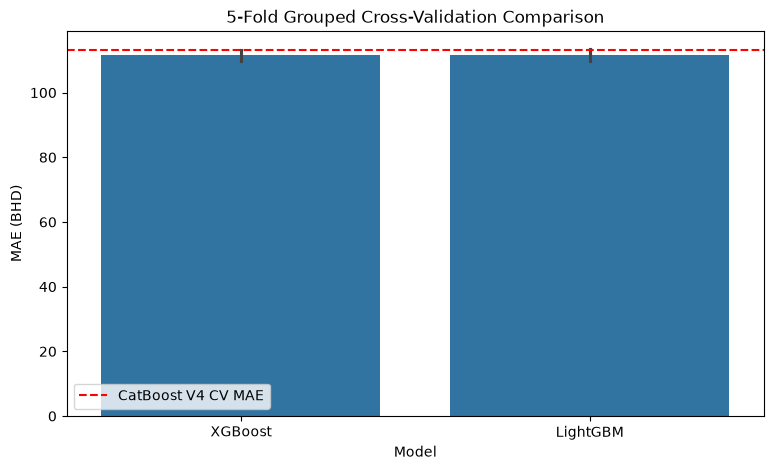

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cv_comparison_df,
    x='Model',
    y='MAE',
    errorbar='sd'
)

plt.axhline(
    y=113.09,
    color='red',
    linestyle='--',
    label='CatBoost V4 CV MAE'
)

plt.title('5-Fold Grouped Cross-Validation Comparison')
plt.ylabel('MAE (BHD)')
plt.xlabel('Model')
plt.legend()
plt.show()

In [101]:
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

xgb_oof = cv_predictions['XGBoost']
lgbm_oof = cv_predictions['LightGBM']

ensemble_results = []

for xgb_weight in np.arange(0, 1.01, 0.1):

    lgbm_weight = 1 - xgb_weight

    ensemble_pred = (
        xgb_weight * xgb_oof +
        lgbm_weight * lgbm_oof
    )

    ensemble_mae = mean_absolute_error(
        y_cv, ensemble_pred
    )

    ensemble_results.append({
        'XGBoost Weight': round(xgb_weight, 2),
        'LightGBM Weight': round(lgbm_weight, 2),
        'OOF MAE': ensemble_mae
    })

ensemble_results_df = pd.DataFrame(ensemble_results)

display(
    ensemble_results_df.sort_values('OOF MAE')
)

,XGBoost Weight,LightGBM Weight,OOF MAE
5,0.5,0.5,110.756572
6,0.6,0.4,110.782415
4,0.4,0.6,110.805154
7,0.7,0.3,110.872724
3,0.3,0.7,110.916120
8,0.8,0.2,111.029764
2,0.2,0.8,111.080788
9,0.9,0.1,111.247009
1,0.1,0.9,111.304001
10,1.0,0.0,111.538892


In [102]:
best_ensemble = ensemble_results_df.loc[
    ensemble_results_df['OOF MAE'].idxmin()
]

best_xgb_weight = best_ensemble['XGBoost Weight']
best_lgbm_weight = best_ensemble['LightGBM Weight']

print("Best Ensemble")
print("-" * 40)

print(f"XGBoost weight: {best_xgb_weight:.2f}")
print(f"LightGBM weight: {best_lgbm_weight:.2f}")
print(f"Ensemble OOF MAE: {best_ensemble['OOF MAE']:.2f} BHD")

Best Ensemble
----------------------------------------
XGBoost weight: 0.50
LightGBM weight: 0.50
Ensemble OOF MAE: 110.76 BHD


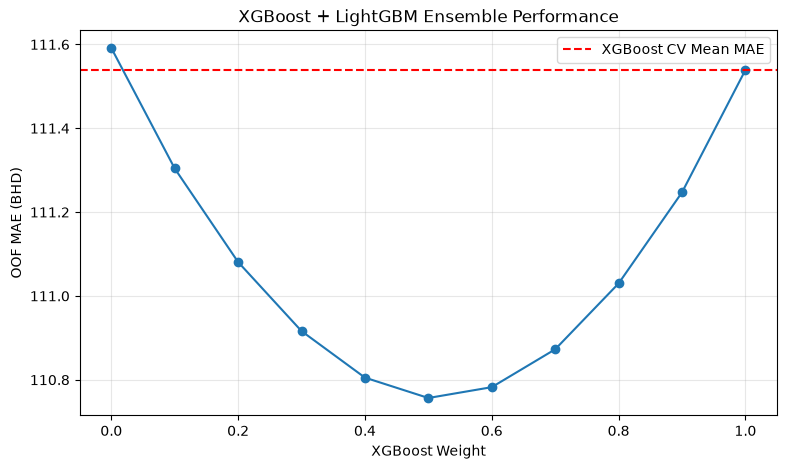

In [103]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    ensemble_results_df['XGBoost Weight'],
    ensemble_results_df['OOF MAE'],
    marker='o'
)

plt.axhline(
    111.54,
    color='red',
    linestyle='--',
    label='XGBoost CV Mean MAE'
)

plt.xlabel('XGBoost Weight')
plt.ylabel('OOF MAE (BHD)')
plt.title('XGBoost + LightGBM Ensemble Performance')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [104]:
# CatBoost out-of-fold predictions
cat_oof = np.full(len(X_cv), np.nan)

for fold, (train_index, val_index) in enumerate(
    gkf.split(X_cv, y_cv, groups_cv)
):
    cat_oof[val_index] = cv_models[fold].predict(
        X_cv.iloc[val_index]
    )

print(
    "CatBoost OOF MAE:",
    mean_absolute_error(y_cv, cat_oof)
)

CatBoost OOF MAE: 113.09275596052473


In [105]:
ensemble_3_results = []

for w_xgb in np.arange(0, 1.01, 0.1):
    for w_lgbm in np.arange(0, 1.01 - w_xgb, 0.1):

        w_cat = round(1 - w_xgb - w_lgbm, 10)

        if w_cat < 0:
            continue

        pred = (
            w_xgb * xgb_oof +
            w_lgbm * lgbm_oof +
            w_cat * cat_oof
        )

        mae = mean_absolute_error(y_cv, pred)

        ensemble_3_results.append({
            'XGBoost': round(w_xgb, 2),
            'LightGBM': round(w_lgbm, 2),
            'CatBoost': round(w_cat, 2),
            'OOF MAE': mae
        })

ensemble_3_df = pd.DataFrame(ensemble_3_results)

display(
    ensemble_3_df.sort_values('OOF MAE').head(10)
)

,XGBoost,LightGBM,CatBoost,OOF MAE
49,0.5,0.4,0.1,110.713430
43,0.4,0.5,0.1,110.724011
42,0.4,0.4,0.2,110.724976
48,0.5,0.3,0.2,110.750666
50,0.5,0.5,0.0,110.756572
35,0.3,0.5,0.2,110.765533
54,0.6,0.3,0.1,110.773662
55,0.6,0.4,-0.0,110.782415
36,0.3,0.6,0.1,110.799322
44,0.4,0.6,-0.0,110.805154


In [106]:
best_ensemble_3 = ensemble_3_df.loc[
    ensemble_3_df['OOF MAE'].idxmin()
]

print("Best Three-Model Ensemble")
print("-" * 40)

print(f"XGBoost weight: {best_ensemble_3['XGBoost']:.2f}")
print(f"LightGBM weight: {best_ensemble_3['LightGBM']:.2f}")
print(f"CatBoost weight: {best_ensemble_3['CatBoost']:.2f}")

print(
    f"Ensemble OOF MAE: "
    f"{best_ensemble_3['OOF MAE']:.2f} BHD"
)

Best Three-Model Ensemble
----------------------------------------
XGBoost weight: 0.50
LightGBM weight: 0.40
CatBoost weight: 0.10
Ensemble OOF MAE: 110.71 BHD


In [107]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

preprocessor_hgb = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'),
     numerical_features_v3),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(
            strategy='constant',
            fill_value='Unknown'
        )),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ]), categorical_features_v3)
])

In [108]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_model = Pipeline([
    ('preprocessor', preprocessor_hgb),

    ('model', HistGradientBoostingRegressor(
        loss='absolute_error',
        max_iter=1000,
        learning_rate=0.05,
        max_leaf_nodes=31,
        max_depth=8,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42
    ))
])

hgb_model.fit(X_train_v3, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['bedrooms_num','bathrooms_num','area_sqm_num',...,'location_clean', 'location_full_clean','include_w_e_clean']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automaticall

In [109]:
from sklearn.metrics import mean_absolute_error

hgb_train_pred = hgb_model.predict(X_train_v3)
hgb_val_pred = hgb_model.predict(X_val_v3)

hgb_train_mae = mean_absolute_error(
    y_train, hgb_train_pred
)

hgb_val_mae = mean_absolute_error(
    y_val, hgb_val_pred
)

print("HistGradientBoosting Results")
print("-" * 40)

print(f"Training MAE: {hgb_train_mae:.2f} BHD")
print(f"Validation MAE: {hgb_val_mae:.2f} BHD")

print("-" * 40)

print(
    f"Difference from XGBoost: "
    f"{xgb_val_mae - hgb_val_mae:.2f} BHD"
)

HistGradientBoosting Results
----------------------------------------
Training MAE: 111.04 BHD
Validation MAE: 114.38 BHD
----------------------------------------
Difference from XGBoost: -5.13 BHD


In [110]:
print("Numerical Features:")
print("-" * 40)

for feature in numerical_features_v3:
    print(feature)

print("\nCategorical Features:")
print("-" * 40)

for feature in categorical_features_v3:
    print(feature)

print("\nTotal Features:", len(features_v3))

Numerical Features:
----------------------------------------
bedrooms_num
bathrooms_num
area_sqm_num
maid_room
latitude
longitude
has_pool
has_gym
has_parking
has_balcony
has_security
has_sea_view
has_ac
has_kitchen_appliances
has_garden
has_maid_service
amenities_count
amenities_text_available

Categorical Features:
----------------------------------------
property_type_clean
governorate_main
neighborhood
furnished_clean
city_clean
location_clean
location_full_clean
include_w_e_clean

Total Features: 26


In [111]:
print("Original training shape:", df.shape)
print("Cleaned training shape:", df_clean.shape)
print("Test shape:", test.shape)

print("\nRemoved training rows:")
print(len(df) - len(df_clean))

print("\nMissing target values:")
print(df['rent'].isna().sum())

print("\nTest Property IDs:")
print(test['Property_id'].nunique())

Original training shape: (32090, 42)
Cleaned training shape: (32059, 65)
Test shape: (3566, 40)

Removed training rows:
31

Missing target values:
0

Test Property IDs:
3566


In [112]:
for col in ['property_type', 'governorate', 'offer']:

    train_values = set(df[col].dropna().astype(str))
    test_values = set(test[col].dropna().astype(str))

    unseen = test_values - train_values

    print(f"\n{col}")
    print("Unseen test categories:", unseen)


property_type
Unseen test categories: set()

governorate
Unseen test categories: set()

offer
Unseen test categories: set()


In [113]:
# Check whether our 26 engineered features
# already exist in the test dataset

missing_features = [
    col for col in features_v3
    if col not in test.columns
]

print("Features missing from test:")
print("-" * 40)

for col in missing_features:
    print(col)

print("\nTotal missing:", len(missing_features))

# Confirm training features
print("\nTraining features available:",
      all(col in df_clean.columns for col in features_v3))

Features missing from test:
----------------------------------------
bedrooms_num
bathrooms_num
area_sqm_num
maid_room
has_pool
has_gym
has_parking
has_balcony
has_security
has_sea_view
has_ac
has_kitchen_appliances
has_garden
has_maid_service
amenities_count
amenities_text_available
property_type_clean
governorate_main
neighborhood
furnished_clean
city_clean
location_clean
location_full_clean
include_w_e_clean

Total missing: 24

Training features available: True


In [114]:
columns_to_inspect = [
    'bedrooms', 'bedrooms_num',
    'bathrooms', 'bathrooms_num',
    'area_sqm', 'area_sqm_num',
    'property_type', 'property_type_clean',
    'governorate', 'governorate_main',
    'location', 'neighborhood',
    'furnished', 'furnished_clean',
    'title', 'maid_room'
]

display(
    df_clean[columns_to_inspect]
    .sample(15, random_state=42)
)

,bedrooms,bedrooms_num,bathrooms,bathrooms_num,area_sqm,area_sqm_num,property_type,property_type_clean,governorate,governorate_main,location,neighborhood,furnished,furnished_clean,title,maid_room
8499,2,2.0,3,3.0,135.0,135.0,Apartment,Apartment,Capital Governorate,Capital Governorate,NaN,Unknown,YES,YES,HOT | MODERN | LOWER FLOOR | AMENITIES | LUXURY |,0
26166,2,2.0,2,2.0,"1,184 sqft / 110 sqm",110.0,Apartment,Apartment,Muharraq Governorate,Muharraq Governorate,NaN,Unknown,NaN,UNKNOWN,1 BEDROOM | 2 BEDROOM | 3 BEDROOM APARTMENTS,0
10121,2,2.0,2,2.0,"1,184 sqft / 110 sqm",110.0,Apartment,Apartment,Capital Governorate,Capital Governorate,NaN,Unknown,NaN,UNKNOWN,Spacious 2BHK|Housekeeping|Free Internet,0
24826,2,2.0,2,2.0,"1,076 sqft / 100 sqm",100.0,Apartment,Apartment,Capital Governorate,Capital Governorate,NaN,Unknown,NaN,UNKNOWN,New I Modern I Great Fescilites I Balcony,0
18680,1,1.0,2,2.0,80.0,80.0,Apartment,Apartment,Muharraq Governorate,Muharraq Governorate,NaN,Unknown,NaN,UNKNOWN,NaN,0
27294,2,2.0,4,4.0,140.0,140.0,Apartment,Apartment,Muharraq Governorate,Muharraq Governorate,Hanging Garden,Unknown,NaN,UNKNOWN,NaN,0
10082,3,3.0,6,6.0,244.0,244.0,Villa,Villa,Muharraq Governorate,Muharraq Governorate,NaN,Unknown,NaN,UNKNOWN,NaN,0
25839,2,2.0,3,3.0,140.0,140.0,Apartment,Apartment,Capital Governorate,Capital Governorate,NaN,Unknown,YES,YES,2BHK|FURNISHED APARTMENT|PRIME LOCATION|INCLUS...,0
28962,3,3.0,4,4.0,350.0,350.0,Villa,Villa,"Capital Governorate, Manama",Capital Governorate,NaN,Manama,PARTLY,PARTLY,Spacious 3BR Villa | 4 Bathrooms | Maid's Room,0
17712,2,2.0,3,3.0,"1,023 sqft / 95 sqm",95.0,Apartment,Apartment,Capital Governorate,Capital Governorate,NaN,Unknown,NaN,UNKNOWN,SUPER LUXURIOUS | SEA VIEW | PREMIUM LAYOUT,0


In [115]:
categorical_check = [
    'property_type_clean',
    'governorate_main',
    'furnished_clean',
    'neighborhood'
]

for col in categorical_check:
    print(f"\n{col}")
    print("-" * 40)

    print(
        df_clean[col]
        .value_counts(dropna=False)
        .head(15)
    )


property_type_clean
----------------------------------------
property_type_clean
Apartment                       25001
Villa                            6086
Compound                          350
Duplex                            292
Penthouse                         182
Townhouse                          51
Whole Building                     49
Hotel Apartment                    19
Bulk Rent Unit                     12
Short Term & Hotel Apartment        9
Bungalow                            3
Land                                3
Chalet                              2
Name: count, dtype: int64

governorate_main
----------------------------------------
governorate_main
Capital Governorate     15195
Muharraq Governorate     8731
Northern Governorate     6097
Central Governorate      1110
Southern Governorate      926
Name: count, dtype: int64

furnished_clean
----------------------------------------
furnished_clean
UNKNOWN    17730
YES        10080
PARTLY      3336
NO           913
Name

In [116]:
for original, engineered in [
    ('bedrooms', 'bedrooms_num'),
    ('bathrooms', 'bathrooms_num'),
    ('area_sqm', 'area_sqm_num')
]:
    print(f"\n{original} -> {engineered}")
    print("-" * 40)

    display(
        df_clean[[original, engineered]]
        .drop_duplicates()
        .head(25)
    )


bedrooms -> bedrooms_num
----------------------------------------


,bedrooms,bedrooms_num
0,studio,0.0
1,1,1.0
2,5,5.0
3,3,3.0
5,2,2.0
9,4,4.0
24,3+ Maid,3.0
40,6+ Maid,6.0
59,4+ Maid,4.0
122,2+ Maid,2.0



bathrooms -> bathrooms_num
----------------------------------------


,bathrooms,bathrooms_num
0,1,1.0
2,5,5.0
3,3,3.0
4,2,2.0
9,4,4.0
16,7+,7.0
18,7,7.0
88,6,6.0
268,10,10.0
5046,NaN,NaN



area_sqm -> area_sqm_num
----------------------------------------


,area_sqm,area_sqm_num
0,43.0,43.0
1,700 sqft / 65 sqm,65.0
2,"4,306 sqft / 400 sqm",400.0
3,160.0,160.0
4,80.0,80.0
5,120.0,120.0
6,91.0,91.0
7,500.0,500.0
8,"1,292 sqft / 120 sqm",120.0
9,350.0,350.0


In [117]:

import pandas as pd

def parse_bedrooms(series):
    s = series.astype("string").str.lower().str.strip()
    s = s.str.replace(r"^studio", "0", regex=True)
    return pd.to_numeric(
        s.str.extract(r"(\d+)", expand=False),
        errors="coerce"
    )

def parse_bathrooms(series):
    s = series.astype("string").str.lower().str.strip()
    return pd.to_numeric(
        s.str.extract(r"(\d+)", expand=False),
        errors="coerce"
    )

def parse_area(series):
    s = series.astype("string").str.lower().str.strip()

    # Prefer the sqm number when both sqft and sqm appear
    sqm = s.str.extract(
        r"/\s*([\d,]+(?:\.\d+)?)\s*sqm",
        expand=False
    )

    plain = s.str.extract(
        r"^\s*([\d,]+(?:\.\d+)?)",
        expand=False
    )

    result = sqm.fillna(plain).str.replace(
        ",", "", regex=False
    )

    return pd.to_numeric(result, errors="coerce")

In [118]:
checks = {
    "bedrooms_num": parse_bedrooms(df_clean["bedrooms"]),
    "bathrooms_num": parse_bathrooms(df_clean["bathrooms"]),
    "area_sqm_num": parse_area(df_clean["area_sqm"])
}

for col, calculated in checks.items():
    original = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

    matches = (
        calculated.eq(original) |
        (calculated.isna() & original.isna())
    ).fillna(False)

    print(f"{col}: {matches.mean():.2%} match")
    print("Mismatched rows:", (~matches).sum())
    print("-" * 40)

bedrooms_num: 100.00% match
Mismatched rows: 0
----------------------------------------
bathrooms_num: 100.00% match
Mismatched rows: 0
----------------------------------------
area_sqm_num: 100.00% match
Mismatched rows: 0
----------------------------------------


In [119]:
categorical_pairs = [
    ("property_type", "property_type_clean"),
    ("furnished", "furnished_clean"),
    ("city", "city_clean"),
    ("location", "location_clean"),
    ("location_full", "location_full_clean"),
    ("include_w_e", "include_w_e_clean")
]

for original, engineered in categorical_pairs:
    print(f"\n{original} -> {engineered}")
    print("-" * 50)

    display(
        df_clean[[original, engineered]]
        .drop_duplicates()
        .head(15)
    )


property_type -> property_type_clean
--------------------------------------------------


,property_type,property_type_clean
0,Apartment,Apartment
2,Compound,Compound
7,Villa,Villa
153,Whole Building,Whole Building
167,Duplex,Duplex
246,Penthouse,Penthouse
355,Short Term & Hotel Apartment,Short Term & Hotel Apartment
905,Townhouse,Townhouse
2151,Bulk Rent Unit,Bulk Rent Unit
2326,Hotel Apartment,Hotel Apartment



furnished -> furnished_clean
--------------------------------------------------


,furnished,furnished_clean
0,YES,YES
1,NaN,UNKNOWN
7,PARTLY,PARTLY
11,NO,NO



city -> city_clean
--------------------------------------------------


,city,city_clean
0,NaN,Unknown
4,Amwaj Islands,Amwaj Islands
5,Busaiteen,Busaiteen
6,Dilmunia Island,Dilmunia Island
12,Janabiya,Janabiya
15,Reef Island,Reef Island
18,Saar,Saar
35,Al Juffair,Al Juffair
45,Hamala,Hamala
51,Diyar Al Muharraq,Diyar Al Muharraq



location -> location_clean
--------------------------------------------------


,location,location_clean
0,NaN,Unknown
4,Al Marsa Floating City,Al Marsa Floating City
6,The Treasure,The Treasure
21,The Lagoon,The Lagoon
31,Tala Island,Tala Island
51,Marassi Boulevard,Marassi Boulevard
62,Um Al Hasam,Um Al Hasam
67,Al Burhama,Al Burhama
86,Sanabis,Sanabis
110,Amwaj Avenue,Amwaj Avenue



location_full -> location_full_clean
--------------------------------------------------


,location_full,location_full_clean
0,"Sanabis, Manama, Capital Governorate","Sanabis, Manama, Capital Governorate"
1,NaN,Unknown
3,"Seef, Capital Governorate","Seef, Capital Governorate"
7,"Janabiya, Northern Governorate","Janabiya, Northern Governorate"
9,"Busaiteen, Muharraq Governorate","Busaiteen, Muharraq Governorate"
10,"Al Juffair, Capital Governorate","Al Juffair, Capital Governorate"
11,"Hidd, Muharraq Governorate","Hidd, Muharraq Governorate"
14,"Bu Kowarah, Riffa, Southern Governorate","Bu Kowarah, Riffa, Southern Governorate"
19,"Reef Island, Capital Governorate","Reef Island, Capital Governorate"
20,"Alhajiyat, Riffa, Southern Governorate","Alhajiyat, Riffa, Southern Governorate"



include_w_e -> include_w_e_clean
--------------------------------------------------


,include_w_e,include_w_e_clean
0,inclusive,inclusive
1,Inclusive,inclusive
2,Exclusive,exclusive
4,NaN,unknown
7,notSelected,notselected
124,exclusive,exclusive


In [120]:
display(
    df_clean[
        ["governorate", "governorate_main", "neighborhood"]
    ]
    .drop_duplicates()
    .head(25)
)

,governorate,governorate_main,neighborhood
0,"Capital Governorate, Manama",Capital Governorate,Manama
1,Capital Governorate,Capital Governorate,Unknown
2,Northern Governorate,Northern Governorate,Unknown
4,Muharraq Governorate,Muharraq Governorate,Unknown
14,"Southern Governorate, Riffa",Southern Governorate,Riffa
50,Central Governorate,Central Governorate,Unknown
58,"Muharraq Governorate, Diyar Al Muharraq",Muharraq Governorate,Diyar Al Muharraq
61,"Muharraq Governorate, Amwaj Islands",Muharraq Governorate,Amwaj Islands
65,"Muharraq Governorate, Dilmunia Island",Muharraq Governorate,Dilmunia Island
99,Southern Governorate,Southern Governorate,Unknown


In [121]:
display(
    df_clean[
        ["bedrooms", "maid_room"]
    ]
    .drop_duplicates()
    .head(25)
)

print("\nMaid room distribution:")
print(df_clean["maid_room"].value_counts(dropna=False))

,bedrooms,maid_room
0,studio,0
1,1,0
2,5,0
3,3,0
5,2,0
9,4,0
24,3+ Maid,1
40,6+ Maid,1
59,4+ Maid,1
122,2+ Maid,1



Maid room distribution:
maid_room
0    30058
1     2001
Name: count, dtype: int64


In [122]:
def create_categorical_features(data):
    data = data.copy()

    # Property type
    data["property_type_clean"] = (
        data["property_type"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
    )

    # Furnished
    data["furnished_clean"] = (
        data["furnished"]
        .fillna("UNKNOWN")
        .astype(str)
        .str.strip()
        .str.upper()
    )

    # Location features
    for col in ["city", "location", "location_full"]:
        data[col + "_clean"] = (
            data[col]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
        )

    # Water and electricity
    data["include_w_e_clean"] = (
        data["include_w_e"]
        .fillna("unknown")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # Governorate and neighborhood
    gov_parts = (
        data["governorate"]
        .fillna("Unknown")
        .astype(str)
        .str.split(",", n=1, expand=True)
    )

    data["governorate_main"] = (
        gov_parts[0].str.strip()
    )

    if 1 in gov_parts.columns:
        data["neighborhood"] = (
            gov_parts[1]
            .fillna("Unknown")
            .str.strip()
        )
    else:
        data["neighborhood"] = "Unknown"

    # Maid room
    data["maid_room"] = (
        data["bedrooms"]
        .astype("string")
        .str.contains("maid", case=False, na=False)
        .astype(int)
    )

    return data

In [123]:
df_check = create_categorical_features(df_clean)

columns_to_verify = [
    "property_type_clean",
    "furnished_clean",
    "city_clean",
    "location_clean",
    "location_full_clean",
    "include_w_e_clean",
    "governorate_main",
    "neighborhood",
    "maid_room"
]

print("Categorical Feature Verification")
print("-" * 55)

for col in columns_to_verify:

    original = df_clean[col]
    reconstructed = df_check[col]

    matches = (
        original.eq(reconstructed) |
        (original.isna() & reconstructed.isna())
    ).fillna(False)

    accuracy = matches.mean() * 100

    print(
        f"{col:25s} "
        f"{accuracy:7.2f}% match | "
        f"Mismatch: {(~matches).sum()}"
    )

Categorical Feature Verification
-------------------------------------------------------
property_type_clean        100.00% match | Mismatch: 0
furnished_clean            100.00% match | Mismatch: 0
city_clean                 100.00% match | Mismatch: 0
location_clean             100.00% match | Mismatch: 0
location_full_clean        100.00% match | Mismatch: 0
include_w_e_clean          100.00% match | Mismatch: 0
governorate_main           100.00% match | Mismatch: 0
neighborhood               100.00% match | Mismatch: 0
maid_room                  100.00% match | Mismatch: 0


In [124]:
import pandas as pd

amenity_keywords = {
    'has_pool': r'\b(?:shared|private)\s+pool\b',
    'has_gym': r'\b(?:shared|private)\s+gym\b',
    'has_parking': r'\b(?:covered\s+)?parking\b',
    'has_balcony': r'\bbalcony\b',
    'has_security': r'\bsecurity\b',
    'has_sea_view': r'\bview of water\b',
    'has_ac': r'\bcentral a/c\b',
    'has_kitchen_appliances': r'\bkitchen appliances\b',
    'has_garden': r'\b(?:private|shared)\s+garden\b',
    'has_maid_service': r'\bmaid service\b'
}

def create_amenity_features(data):
    data = data.copy()

    amenities_text = (
        data['amenities']
        .fillna('')
        .astype(str)
        .str.strip()
    )

    # Exclude empty and numeric-only records
    has_text = (
        amenities_text.ne('')
        & ~amenities_text.str.fullmatch(
            r'[\d\s,.]+', na=False
        )
    )

    data['amenities_text_available'] = (
        has_text.astype(int)
    )

    data['amenities_count'] = (
        amenities_text
        .str.split(',')
        .str.len()
        .where(has_text, 0)
        .astype(int)
    )

    for feature, pattern in amenity_keywords.items():
        data[feature] = (
            amenities_text.str.contains(
                pattern,
                case=False,
                regex=True,
                na=False
            )
            & has_text
        ).astype(int)

    return data

In [125]:
df_amenities_check = create_amenity_features(df_clean)

amenity_columns = (
    list(amenity_keywords.keys())
    + ['amenities_count', 'amenities_text_available']
)

print("Amenity Feature Verification")
print("-" * 65)

for col in amenity_columns:
    original = df_clean[col]
    reconstructed = df_amenities_check[col]

    matches = (
        original.eq(reconstructed)
        | (original.isna() & reconstructed.isna())
    ).fillna(False)

    print(
        f"{col:28s} "
        f"{matches.mean() * 100:7.2f}% match | "
        f"Mismatch: {(~matches).sum()}"
    )

Amenity Feature Verification
-----------------------------------------------------------------
has_pool                      100.00% match | Mismatch: 0
has_gym                       100.00% match | Mismatch: 0
has_parking                   100.00% match | Mismatch: 0
has_balcony                   100.00% match | Mismatch: 0
has_security                  100.00% match | Mismatch: 0
has_sea_view                  100.00% match | Mismatch: 0
has_ac                        100.00% match | Mismatch: 0
has_kitchen_appliances        100.00% match | Mismatch: 0
has_garden                    100.00% match | Mismatch: 0
has_maid_service              100.00% match | Mismatch: 0
amenities_count               100.00% match | Mismatch: 0
amenities_text_available      100.00% match | Mismatch: 0


In [126]:
def preprocess_properties(data):
    data = data.copy()

    # Numerical features
    data["bedrooms_num"] = parse_bedrooms(data["bedrooms"])
    data["bathrooms_num"] = parse_bathrooms(data["bathrooms"])
    data["area_sqm_num"] = parse_area(data["area_sqm"])

    # Categorical and maid-room features
    data = create_categorical_features(data)

    # Amenity features
    data = create_amenity_features(data)

    # Ensure coordinate columns are numeric
    for col in ["latitude", "longitude"]:
        data[col] = pd.to_numeric(
            data[col], errors="coerce"
        )

    return data

In [127]:
test_processed = preprocess_properties(test)

X_test_final = test_processed[features_v3].copy()

# Apply the same data types used during training
for col in categorical_features_v3:
    X_test_final[col] = (
        X_test_final[col]
        .fillna("Unknown")
        .astype(str)
    )

for col in numerical_features_v3:
    X_test_final[col] = pd.to_numeric(
        X_test_final[col],
        errors="coerce"
    )

print("Test preprocessing complete!")
print("-" * 45)

print("Original test shape:", test.shape)
print("Processed test shape:", test_processed.shape)
print("Model input shape:", X_test_final.shape)

print("\nMissing values:")
print(X_test_final.isna().sum()[
    X_test_final.isna().sum() > 0
])

Test preprocessing complete!
---------------------------------------------
Original test shape: (3566, 40)
Processed test shape: (3566, 64)
Model input shape: (3566, 26)

Missing values:
bedrooms_num        2
bathrooms_num       2
latitude         1979
longitude        1979
dtype: int64


In [128]:
import numpy as np

assert len(X_test_final) == len(test)
assert len(X_test_final.columns) == 26
assert X_test_final.columns.tolist() == features_v3
assert test["Property_id"].is_unique

assert np.isfinite(
    X_test_final[numerical_features_v3]
    .to_numpy(dtype=float)[
        ~np.isnan(
            X_test_final[numerical_features_v3]
            .to_numpy(dtype=float)
        )
    ]
).all()

print("All test dataset checks passed!")
print("Ready for final model training.")

All test dataset checks passed!
Ready for final model training.


In [129]:
X_full = df_clean[features_v3].copy()
y_full = df_clean["rent"].copy()

for col in categorical_features_v3:
    X_full[col] = (
        X_full[col]
        .fillna("Unknown")
        .astype(str)
    )

for col in numerical_features_v3:
    X_full[col] = pd.to_numeric(
        X_full[col],
        errors="coerce"
    )

print("Full training shape:", X_full.shape)
print("Target shape:", y_full.shape)
print("Test shape:", X_test_final.shape)

assert X_full.columns.tolist() == X_test_final.columns.tolist()
assert y_full.notna().all()

print("Training data ready!")

Full training shape: (32059, 26)
Target shape: (32059,)
Test shape: (3566, 26)
Training data ready!


In [130]:
from sklearn.base import clone

# Reuse the previously evaluated XGBoost pipeline
xgb_final = clone(xgb_model)

xgb_final.fit(X_full, y_full)

xgb_test_pred = xgb_final.predict(X_test_final)

print("XGBoost training complete!")
print("Predictions:", len(xgb_test_pred))
print("Mean predicted rent:", round(xgb_test_pred.mean(), 2))

XGBoost training complete!
Predictions: 3566
Mean predicted rent: 561.28


In [131]:
# Reuse the previously evaluated LightGBM pipeline
lgbm_final = clone(lgbm_model)

lgbm_final.fit(X_full, y_full)

lgbm_test_pred = lgbm_final.predict(X_test_final)

print("LightGBM training complete!")
print("Predictions:", len(lgbm_test_pred))
print("Mean predicted rent:", round(lgbm_test_pred.mean(), 2))

LightGBM training complete!
Predictions: 3566
Mean predicted rent: 556.54


In [132]:

from catboost import CatBoostRegressor

cat_final = CatBoostRegressor(
    iterations=3000,
    depth=8,
    learning_rate=0.03,
    loss_function="MAE",
    random_seed=42,
    verbose=False
)

cat_final.fit(
    X_full,
    y_full,
    cat_features=categorical_features_v3
)

cat_test_pred = cat_final.predict(X_test_final)

print("CatBoost training complete!")
print("Predictions:", len(cat_test_pred))
print("Mean predicted rent:", round(cat_test_pred.mean(), 2))


CatBoost training complete!
Predictions: 3566
Mean predicted rent: 559.21


In [133]:
import numpy as np

ensemble_test_pred = (
    0.50 * xgb_test_pred
    + 0.40 * lgbm_test_pred
    + 0.10 * cat_test_pred
)

print("Final Ensemble Predictions")
print("-" * 45)
print("Number of predictions:", len(ensemble_test_pred))
print("Minimum rent:", round(ensemble_test_pred.min(), 2))
print("Maximum rent:", round(ensemble_test_pred.max(), 2))
print("Average rent:", round(ensemble_test_pred.mean(), 2))
print("Median rent:", round(np.median(ensemble_test_pred), 2))

assert len(ensemble_test_pred) == len(test)
assert np.isfinite(ensemble_test_pred).all()
assert (ensemble_test_pred > 0).all()

print("\nAll prediction checks passed!")

Final Ensemble Predictions
---------------------------------------------
Number of predictions: 3566
Minimum rent: 110.84
Maximum rent: 3707.62
Average rent: 559.18
Median rent: 440.6

All prediction checks passed!


In [134]:
import pandas as pd
import numpy as np

submission = pd.DataFrame({
    "Property_id": test["Property_id"].to_numpy(),
    "Rent": ensemble_test_pred
})

# Final validation
assert submission.shape == (3566, 2)
assert submission.columns.tolist() == ["Property_id", "Rent"]
assert submission["Property_id"].is_unique
assert submission.notna().all().all()
assert np.isfinite(submission["Rent"]).all()
assert (submission["Rent"] > 0).all()

# Save competition submission
submission.to_csv("submission.csv", index=False)

print("Submission saved successfully!")
print("-" * 45)
print("Shape:", submission.shape)
print("Columns:", submission.columns.tolist())
print("Missing values:", submission.isna().sum().sum())

display(submission.head(10))

Submission saved successfully!
---------------------------------------------
Shape: (3566, 2)
Columns: ['Property_id', 'Rent']
Missing values: 0


,Property_id,Rent
0,25c91c33-a523-42f2-8c10-9f340005471d,471.494493
1,6bcb7804-9cd7-4792-8cbe-abb4de65058a,339.647621
2,7b733e67-ec21-4427-95f8-4be3d9d18f6b,955.237995
3,feefd51f-a7d6-45b0-a9eb-200d9f9821b4,345.840793
4,cca286dd-ddc6-41c2-9584-f8e17461220f,468.378482
5,cc9b3f89-6263-4bf8-bbdb-3d8fb8509243,402.202114
6,e70723a0-3c99-4d02-bb58-ea679b3e2053,326.064253
7,08b5bd2c-546f-479d-bae1-ef6ced64cbf0,675.967835
8,a8596600-6030-4229-9c13-1e26fceb4409,461.855470
9,3d5181fe-7bce-4f03-a57b-ed1ef415355f,232.411976


In [135]:
submission_check = pd.read_csv("submission.csv")

print("Final Submission Verification")
print("-" * 45)

print("Shape:", submission_check.shape)
print("Unique IDs:", submission_check["Property_id"].nunique())
print("Average predicted rent:",
      round(submission_check["Rent"].mean(), 2))

assert submission_check.shape == (3566, 2)
assert submission_check["Property_id"].tolist() == (
    test["Property_id"].tolist()
)

print("\nSubmission is ready!")

Final Submission Verification
---------------------------------------------
Shape: (3566, 2)
Unique IDs: 3566
Average predicted rent: 559.18

Submission is ready!
